# Final CCLE comparison: saved models + same-gene correlation baselines

This notebook compares saved 80/20 model results from:

- `results_xgb/`
- `res_xgb_zbig/`
- `results_enet/`
- `res_enet_zbig/`

and adds two simple same-name gene baselines:

- **Pearson same-gene baseline**: for proteins where `full_pearson100[protein, same-name gene] >= 0.7`, predict protein abundance using the same-name RNA gene value.
- **Spearman same-gene baseline**: same idea using `full_spearman100`.

The same-gene baselines are evaluated on a reproducible random 20% test split.

Important: the same-gene baselines use raw gene expression values directly as predictions. Pearson/cosine can be meaningful for direction/ranking, but MSE may look poor if RNA and protein scales differ.

In [6]:
from pathlib import Path
import json
import lzma
import pickle
import re
import warnings

import h5py
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# -----------------------------
# Project paths
# -----------------------------
ROOT = Path.cwd()
DATA_DIR = ROOT / "data"

X_PATH = DATA_DIR / "transcriptomics_filtered.joblib"
Y_PATH = DATA_DIR / "proteomics_matched.joblib"
PEARSON_PATH = DATA_DIR / "full_pearson100.joblib"
SPEARMAN_PATH = DATA_DIR / "full_spearman100.joblib"

MODEL_DIRS = {
    "xgb": ROOT / "results_xgb",
    "xgb_zbig": ROOT / "res_xgb_zbig",
    "enet": ROOT / "results_enet",
    "enet_zbig": ROOT / "res_enet_zbig",
}

# -----------------------------
# Thresholds and display settings
# -----------------------------
RANDOM_SEED = 42
BASELINE_CORR_THRESHOLD = 0.70
TEST_FRACTION = 0.20

PEARSON_GOOD_THRESHOLD = 0.70
COSINE_GOOD_THRESHOLD = 0.70
MSE_GOOD_PERCENTILE = 25   # lower MSE is better; good if MSE <= this percentile among best-MSE rows

MIN_PROTEINS_TO_SHOW_AS_OWN_SEGMENT = 200

# Scaling for same-gene baseline. Leave False to match the requested raw-gene-as-prediction behavior.
SCALE_GENE_BASELINE_WITH_TRAIN_LINEAR_MODEL = False

print("Root:", ROOT)
print("Data dir:", DATA_DIR)
print("Model folders:")
for name, folder in MODEL_DIRS.items():
    print(f"  {name:10s}: {folder}  exists={folder.exists()}")

Root: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison
Data dir: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\data
Model folders:
  xgb       : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\results_xgb  exists=True
  xgb_zbig  : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\res_xgb_zbig  exists=True
  enet      : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\results_enet  exists=True
  enet_zbig : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\res_enet_zbig  exists=True


## 1. Load transcriptomics, proteomics, and correlation matrices

In [7]:
def require_file(path: Path):
    if not path.exists():
        raise FileNotFoundError(f"Missing required file: {path}")
    return path

for p in [X_PATH, Y_PATH, PEARSON_PATH, SPEARMAN_PATH]:
    require_file(p)

X_raw = joblib.load(X_PATH)
Y_raw = joblib.load(Y_PATH)
pearson_corr_obj = joblib.load(PEARSON_PATH)
spearman_corr_obj = joblib.load(SPEARMAN_PATH)

X = X_raw.copy()
Y0 = Y_raw.copy()

X.index = X.index.map(str)
X.columns = X.columns.map(str)
Y0.index = Y0.index.map(str)
Y0.columns = Y0.columns.map(str)

# Detect proteomics orientation and convert to rows=samples, columns=proteins.
x_samples = set(X.index)
y_index_overlap = len(x_samples & set(Y0.index))
y_column_overlap = len(x_samples & set(Y0.columns))

if y_index_overlap >= y_column_overlap:
    Y = Y0.copy()
    proteomics_orientation = "samples_as_rows__proteins_as_columns"
else:
    Y = Y0.T.copy()
    proteomics_orientation = "proteins_as_rows__samples_as_columns__transposed"

Y.index = Y.index.map(str)
Y.columns = Y.columns.map(str)

common_samples = X.index.intersection(Y.index)
X = X.loc[common_samples].copy()
Y = Y.loc[common_samples].copy()

print("Loaded data")
print("- Transcriptomics shape:", X.shape, "(samples x genes)")
print("- Proteomics shape:     ", Y.shape, "(samples x proteins)")
print("- Proteomics orientation:", proteomics_orientation)
print("- Common samples:", len(common_samples))
print("- First samples:", list(common_samples[:5]))
print("- First genes:", list(X.columns[:5]))
print("- First proteins:", list(Y.columns[:5]))

print("\nCorrelation objects:")
print("- Pearson type:", type(pearson_corr_obj), "shape:", getattr(pearson_corr_obj, "shape", None))
print("- Spearman type:", type(spearman_corr_obj), "shape:", getattr(spearman_corr_obj, "shape", None))

Loaded data
- Transcriptomics shape: (369, 22614) (samples x genes)
- Proteomics shape:      (369, 5113) (samples x proteins)
- Proteomics orientation: samples_as_rows__proteins_as_columns
- Common samples: 369
- First samples: ['MDAMB468_BREAST', 'SH4_SKIN', 'AU565_BREAST', 'KMRC1_KIDNEY', 'CAL51_BREAST']
- First genes: ['A1BG', 'A1BG-AS1', 'A1CF', 'A2M', 'A2ML1']
- First proteins: ['A2M', 'AAAS', 'AACS', 'AAGAB', 'AAK1']

Correlation objects:
- Pearson type: <class 'pandas.core.frame.DataFrame'> shape: (5113, 51989)
- Spearman type: <class 'pandas.core.frame.DataFrame'> shape: (5113, 51989)


## 2. Helper functions for metrics, correlation lookup, and H5 result loading

In [8]:
def compute_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = np.isfinite(y_true) & np.isfinite(y_pred)

    out = {
        "test_mse": np.nan,
        "test_pearson_corr": np.nan,
        "test_cosine_similarity": np.nan,
        "n_test_used": int(mask.sum()),
    }
    if mask.sum() == 0:
        return out

    yt = y_true[mask]
    yp = y_pred[mask]
    out["test_mse"] = float(np.mean((yt - yp) ** 2))

    if len(yt) >= 2 and np.std(yt) > 0 and np.std(yp) > 0:
        out["test_pearson_corr"] = float(np.corrcoef(yt, yp)[0, 1])

    denom = float(np.linalg.norm(yt) * np.linalg.norm(yp))
    if denom > 0:
        out["test_cosine_similarity"] = float(np.dot(yt, yp) / denom)

    return out


def as_dataframe_or_none(obj):
    if isinstance(obj, pd.DataFrame):
        df = obj.copy()
        df.index = df.index.map(str)
        df.columns = df.columns.map(str)
        return df
    return None


def get_same_name_corr(corr_obj, protein: str):
    """Robustly extract corr(protein, same-name gene) from several common formats."""
    protein = str(protein)

    # Matrix DataFrame: rows=proteins, columns=genes or vice versa.
    df = as_dataframe_or_none(corr_obj)
    if df is not None:
        if protein in df.index and protein in df.columns:
            try:
                return float(df.loc[protein, protein])
            except Exception:
                pass

        # Long-format table: columns like protein, gene, correlation.
        lower_cols = {c.lower(): c for c in df.columns}
        prot_candidates = ["protein", "protein_name", "target", "target_protein"]
        gene_candidates = ["gene", "feature", "rna", "transcript", "transcript_gene"]
        corr_candidates = [
            c for c in df.columns
            if "corr" in c.lower() or "pearson" in c.lower() or "spearman" in c.lower()
        ]

        prot_col = next((lower_cols[c] for c in prot_candidates if c in lower_cols), None)
        gene_col = next((lower_cols[c] for c in gene_candidates if c in lower_cols), None)
        corr_col = corr_candidates[0] if corr_candidates else None

        if prot_col and gene_col and corr_col:
            sub = df[
                (df[prot_col].astype(str) == protein) &
                (df[gene_col].astype(str) == protein)
            ]
            if len(sub):
                return float(sub.iloc[0][corr_col])

    # Dict: protein -> Series/dict containing same-name gene.
    if isinstance(corr_obj, dict):
        if protein in corr_obj:
            val = corr_obj[protein]
            if isinstance(val, pd.Series):
                val.index = val.index.map(str)
                if protein in val.index:
                    return float(val.loc[protein])
            if isinstance(val, dict) and protein in val:
                return float(val[protein])
        # dict with tuple key
        if (protein, protein) in corr_obj:
            return float(corr_obj[(protein, protein)])

    return np.nan


def safe_float(x):
    try:
        if x is None:
            return np.nan
        v = float(x)
        return v if np.isfinite(v) else np.nan
    except Exception:
        return np.nan


def safe_int(x):
    try:
        if x is None:
            return np.nan
        return int(x)
    except Exception:
        return np.nan


def _decode_json_dataset(ds):
    """
    Decode JSON stored as:
      - uint8 array
      - bytes scalar
      - string scalar
      - array of byte strings
    """
    data = ds[()]

    if isinstance(data, bytes):
        raw = data
    elif isinstance(data, str):
        raw = data.encode("utf-8")
    else:
        arr = np.asarray(data)
        if arr.dtype.kind in {"S", "U", "O"}:
            raw = b"".join(
                x if isinstance(x, bytes) else str(x).encode("utf-8")
                for x in arr.ravel()
            )
        else:
            raw = bytes(arr.astype(np.uint8).ravel())

    return json.loads(raw.decode("utf-8"))


def read_json_dataset(h5, candidates):
    """
    Try all possible JSON paths used by different XGB/ENet H5 pipeline versions.
    """
    for key in candidates:
        if key in h5:
            try:
                return _decode_json_dataset(h5[key])
            except Exception:
                pass
    return {}


def get_attr_float(group_or_h5, key):
    try:
        if group_or_h5 is not None and key in group_or_h5.attrs:
            return safe_float(group_or_h5.attrs.get(key))
    except Exception:
        pass
    return np.nan


def get_attr_int(group_or_h5, key):
    try:
        if group_or_h5 is not None and key in group_or_h5.attrs:
            return safe_int(group_or_h5.attrs.get(key))
    except Exception:
        pass
    return np.nan


def protein_from_filename(path: Path):
    name = path.stem
    for token in ["_xgb_8020_", "_enet_8020_"]:
        if token in name:
            return name.split(token)[0]
    return name.split("_")[0]


def parse_filename_info(path: Path):
    """
    Parse filenames such as:
      A2M_xgb_8020_zscore_fast_k2000.h5
      A2M_xgb_8020_qbin50_tiny_k50.h5
      A2M_enet_8020_zscore_fast_k5000.h5
    """
    path = Path(path)
    stem = path.stem
    tokens = stem.split("_")

    model_family = "unknown"
    if "_xgb_8020_" in stem:
        model_family = "xgb"
    elif "_enet_8020_" in stem:
        model_family = "enet"

    protein = protein_from_filename(path)

    normalization = "unknown"
    grid_preset = "unknown"
    select_k = np.nan

    known_norms = {
        "none", "zscore", "rank", "ranking", "binning",
        "qbin5", "qbin10", "qbin20", "qbin50", "qbin100",
    }

    for tok in tokens:
        if tok in known_norms or re.fullmatch(r"qbin\d+", tok):
            normalization = tok
            break

    for tok in tokens:
        if tok in {"tiny", "fast", "current"}:
            grid_preset = tok
            break

    for tok in tokens:
        m = re.fullmatch(r"k(\d+)", tok)
        if m:
            select_k = int(m.group(1))
            break

    return {
        "protein": protein,
        "model_family": model_family,
        "normalization": normalization,
        "grid_preset": grid_preset,
        "select_k": select_k,
    }


def load_artifact_from_h5(path: Path):
    """
    Optional helper. Do not use during full scan unless needed,
    because loading thousands of pickled models is slow.
    """
    path = Path(path)
    with h5py.File(path, "r") as h5:
        if "model/artifact_pickle_xz" not in h5:
            return None
        payload = h5["model/artifact_pickle_xz"][:]

    return pickle.loads(lzma.decompress(np.asarray(payload, dtype=np.uint8).tobytes()))


def _read_best_params(h5, summary):
    """
    Read best params from summary if present, otherwise model JSON datasets.
    """
    for key in ["best_params", "params", "model_params"]:
        if key in summary:
            return summary.get(key)

    for key in ["model/best_params_json", "model/params_json"]:
        if key in h5:
            try:
                return _decode_json_dataset(h5[key])
            except Exception:
                pass

    return {}


def load_h5_summary(path: Path, source_label: str):
    """
    Robust loader for both XGB and ENet H5 formats.

    Important fix:
    XGB 80/20 files often store metrics as /metrics attrs or /metrics/summary_json,
    not only /summary/json or /metrics/json.
    """
    path = Path(path)
    info = parse_filename_info(path)

    row = {
        "protein": info["protein"],
        "run_label": None,
        "model_family": info["model_family"],
        "source_folder": source_label,
        "normalization": info["normalization"],
        "grid_preset": info["grid_preset"],
        "select_k": info["select_k"],
        "h5_path": str(path),
        "file": path.name,
        "file_size_mb": path.stat().st_size / (1024 ** 2),
        "test_mse": np.nan,
        "test_pearson_corr": np.nan,
        "test_cosine_similarity": np.nan,
        "selected_feature_count": np.nan,
        "train_n": np.nan,
        "test_n": np.nan,
        "best_params": {},
        "load_error": None,
    }

    try:
        with h5py.File(path, "r") as h5:
            root_attrs = dict(h5.attrs)
            metrics_group = h5.get("metrics", None)
            model_group = h5.get("model", None)
            samples_group = h5.get("samples", None)

            summary = read_json_dataset(
                h5,
                [
                    "summary/json",
                    "metrics/json",
                    "metrics/summary_json",
                    "metrics/summary",
                ],
            )

            # Identifiers
            row["protein"] = str(summary.get("protein") or root_attrs.get("protein") or row["protein"])
            row["normalization"] = str(summary.get("normalization") or root_attrs.get("normalization") or row["normalization"])
            row["model_family"] = str(summary.get("model_family") or row["model_family"])
            row["grid_preset"] = str(
                summary.get("grid_preset")
                or summary.get("grid")
                or root_attrs.get("grid_preset", row["grid_preset"])
                or row["grid_preset"]
            )
            row["select_k"] = safe_int(
                summary.get("select_k")
                or root_attrs.get("select_k", row["select_k"])
                or row["select_k"]
            )

            # Metrics: summary first, then /metrics attrs, then root attrs.
            row["test_mse"] = safe_float(summary.get("test_mse", summary.get("mse", np.nan)))
            if not np.isfinite(row["test_mse"]):
                row["test_mse"] = get_attr_float(metrics_group, "test_mse")
            if not np.isfinite(row["test_mse"]):
                row["test_mse"] = get_attr_float(metrics_group, "mse")
            if not np.isfinite(row["test_mse"]):
                row["test_mse"] = get_attr_float(h5, "test_mse")

            row["test_pearson_corr"] = safe_float(
                summary.get("test_pearson_corr", summary.get("pearson_corr", np.nan))
            )
            if not np.isfinite(row["test_pearson_corr"]):
                row["test_pearson_corr"] = get_attr_float(metrics_group, "test_pearson_corr")
            if not np.isfinite(row["test_pearson_corr"]):
                row["test_pearson_corr"] = get_attr_float(metrics_group, "pearson_corr")
            if not np.isfinite(row["test_pearson_corr"]):
                row["test_pearson_corr"] = get_attr_float(h5, "test_pearson_corr")

            row["test_cosine_similarity"] = safe_float(
                summary.get(
                    "test_cosine_similarity",
                    summary.get(
                        "cosine_similarity",
                        summary.get("vector_cosine_similarity_all_loo", np.nan),
                    ),
                )
            )
            if not np.isfinite(row["test_cosine_similarity"]):
                row["test_cosine_similarity"] = get_attr_float(metrics_group, "test_cosine_similarity")
            if not np.isfinite(row["test_cosine_similarity"]):
                row["test_cosine_similarity"] = get_attr_float(metrics_group, "cosine_similarity")
            if not np.isfinite(row["test_cosine_similarity"]):
                row["test_cosine_similarity"] = get_attr_float(metrics_group, "vector_cosine_similarity_all_loo")
            if not np.isfinite(row["test_cosine_similarity"]):
                row["test_cosine_similarity"] = get_attr_float(h5, "test_cosine_similarity")

            # Train/test sample counts
            train_samples = summary.get("train_samples", [])
            test_samples = summary.get("test_samples", [])
            if isinstance(train_samples, list):
                row["train_n"] = len(train_samples)
            if isinstance(test_samples, list):
                row["test_n"] = len(test_samples)

            if samples_group is not None:
                if "train_samples" in samples_group:
                    row["train_n"] = len(samples_group["train_samples"])
                if "test_samples" in samples_group:
                    row["test_n"] = len(samples_group["test_samples"])

            # Selected features
            selected_features = summary.get("selected_features", None)
            if isinstance(selected_features, list):
                row["selected_feature_count"] = len(selected_features)

            if model_group is not None:
                if "selected_feature_count" in model_group.attrs:
                    row["selected_feature_count"] = safe_int(model_group.attrs.get("selected_feature_count"))
                elif "selected_features" in model_group:
                    row["selected_feature_count"] = len(model_group["selected_features"])

            row["best_params"] = _read_best_params(h5, summary)

    except Exception as e:
        row["load_error"] = f"{type(e).__name__}: {e}"

    # Clean model family from source label if filename was ambiguous
    if row["model_family"] == "unknown":
        if "xgb" in str(source_label).lower():
            row["model_family"] = "xgb"
        elif "enet" in str(source_label).lower():
            row["model_family"] = "enet"

    # Keep labels concise but distinct.
    label_bits = [str(source_label), str(row["normalization"])]
    if row["grid_preset"] not in {"", "unknown", "None", "nan"}:
        label_bits.append(str(row["grid_preset"]))
    if pd.notna(row["select_k"]):
        label_bits.append(f"k{int(row['select_k'])}")
    row["run_label"] = " | ".join(label_bits)

    return row

## 3. Load saved XGB/ENet result summaries and merge with same-gene baselines

In [9]:
# ============================================================
# Load saved XGB/ENet result summaries
# Do NOT build all_results here yet.
# The same-gene baselines will be rebuilt after reading the H5 test split.
# ============================================================

model_rows = []
folder_counts = {}

for label, folder in MODEL_DIRS.items():
    folder = Path(folder)
    files = sorted(folder.glob("*.h5")) if folder.exists() else []
    folder_counts[label] = len(files)

    for path in files:
        row = load_h5_summary(path, label)

        # Make sure h5_path exists even if load_h5_summary did not include it.
        if "h5_path" not in row:
            row["h5_path"] = str(path)

        model_rows.append(row)

model_results = pd.DataFrame(model_rows)

if len(model_results):
    for c in [
        "test_mse",
        "test_pearson_corr",
        "test_cosine_similarity",
        "selected_feature_count",
        "train_n",
        "test_n",
        "select_k",
        "file_size_mb",
    ]:
        if c in model_results.columns:
            model_results[c] = pd.to_numeric(model_results[c], errors="coerce")

print("Saved model file counts")
for label, n in folder_counts.items():
    print(f"- {label:12s}: {n:6d} H5 files")

print("\nSaved model result table")
print("- Saved model rows:", len(model_results))
print("- Unique proteins: ", model_results["protein"].nunique() if len(model_results) and "protein" in model_results.columns else 0)

if len(model_results) and "load_error" in model_results.columns:
    n_errors = int(model_results["load_error"].notna().sum())
    print("- H5 load errors:  ", n_errors)

    if n_errors:
        print("\nExample load errors:")
        display(model_results.loc[model_results["load_error"].notna(), ["h5_path", "load_error"]].head(10))

if len(model_results):
    print("\nRows by run_label:")
    display(
        model_results.groupby("run_label")["protein"]
        .nunique()
        .sort_values(ascending=False)
        .to_frame("proteins")
    )

    print("\nMetric availability:")
    display(
        model_results[["test_pearson_corr", "test_cosine_similarity", "test_mse"]]
        .notna()
        .sum()
        .to_frame("nonmissing")
    )

    display(model_results.head())

Saved model file counts
- xgb         :  20462 H5 files
- xgb_zbig    :   5113 H5 files
- enet        :  20602 H5 files
- enet_zbig   :   5113 H5 files

Saved model result table
- Saved model rows: 51290
- Unique proteins:  5113
- H5 load errors:   0

Rows by run_label:


,proteins
run_label,
enet | none | fast | k2000,5113
enet | ranking | fast | k2000,5113
enet | unknown | fast | k2000,5113
enet | zscore | fast | k2000,5113
enet_zbig | zscore | fast | k5000,5113
xgb | none | fast | k2000,5113
xgb | qbin50 | fast | k2000,5113
xgb | rank | fast | k2000,5113
xgb | zscore | fast | k2000,5113



Metric availability:


,nonmissing
test_pearson_corr,50217
test_cosine_similarity,51290
test_mse,51290


,protein,run_label,model_family,source_folder,normalization,grid_preset,select_k,h5_path,file,file_size_mb,test_mse,test_pearson_corr,test_cosine_similarity,selected_feature_count,train_n,test_n,best_params,load_error
0,A2M,xgb | none | fast | k2000,xgb,xgb,none,fast,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_none_fast_k2000.h5,0.120128,0.760331,0.469012,0.554128,2000,295,74,"{'colsample_bytree': 0.6, 'device': 'cpu', 'ga...",None
1,A2M,xgb | none | tiny | k50,xgb,xgb,none,tiny,50,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_none_tiny_k50.h5,0.083029,0.753375,0.477427,0.558124,50,295,74,"{'colsample_bytree': 0.8, 'device': 'cpu', 'ga...",None
2,A2M,xgb | qbin50 | fast | k2000,xgb,xgb,qbin50,fast,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_qbin50_fast_k2000.h5,2.574004,0.751074,0.466232,0.560768,2000,295,74,"{'colsample_bytree': 0.6, 'device': 'cpu', 'ga...",None
3,A2M,xgb | qbin50 | tiny | k50,xgb,xgb,qbin50,tiny,50,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_qbin50_tiny_k50.h5,2.617776,0.778497,0.451791,0.539072,50,295,74,"{'colsample_bytree': 0.8, 'device': 'cpu', 'ga...",None
4,A2M,xgb | rank | fast | k2000,xgb,xgb,rank,fast,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_rank_fast_k2000.h5,7.608312,0.760331,0.469012,0.554128,2000,295,74,"{'colsample_bytree': 0.6, 'device': 'cpu', 'ga...",None


## 4. Build same-gene Pearson/Spearman baseline results on the same 20% test split

In [11]:
# ============================================================
# Rebuild same-gene Pearson/Spearman proxies on the exact H5 test split
# used by XGB/ENet, then create all_results.
#
# This cell is self-contained:
# - reads test_samples from H5 files
# - defines same-gene baseline helper functions if missing
# - rebuilds Pearson/Spearman proxy baselines on the same 20% test set
# - creates all_results
# ============================================================

import hashlib
import json
import numpy as np
import pandas as pd
import h5py

if "SCALE_GENE_BASELINE_WITH_TRAIN_LINEAR_MODEL" not in globals():
    SCALE_GENE_BASELINE_WITH_TRAIN_LINEAR_MODEL = False

# -----------------------------
# Fallback metric helper
# -----------------------------
if "compute_metrics" not in globals():
    def compute_metrics(y_true, y_pred):
        y_true = np.asarray(y_true, dtype=float)
        y_pred = np.asarray(y_pred, dtype=float)
        mask = np.isfinite(y_true) & np.isfinite(y_pred)

        out = {
            "test_mse": np.nan,
            "test_pearson_corr": np.nan,
            "test_cosine_similarity": np.nan,
            "n_test_used": int(mask.sum()),
        }

        if mask.sum() == 0:
            return out

        yt = y_true[mask]
        yp = y_pred[mask]

        out["test_mse"] = float(np.mean((yt - yp) ** 2))

        if len(yt) >= 2 and np.std(yt) > 0 and np.std(yp) > 0:
            out["test_pearson_corr"] = float(np.corrcoef(yt, yp)[0, 1])

        denom = float(np.linalg.norm(yt) * np.linalg.norm(yp))
        if denom > 0:
            out["test_cosine_similarity"] = float(np.dot(yt, yp) / denom)

        return out


# -----------------------------
# H5 split-reading helpers
# -----------------------------
def _decode_h5_string_array(x):
    arr = np.asarray(x)

    if arr.shape == ():
        arr = arr.reshape(1)

    out = []
    for v in arr.ravel():
        if isinstance(v, bytes):
            out.append(v.decode("utf-8"))
        elif isinstance(v, np.bytes_):
            out.append(bytes(v).decode("utf-8"))
        else:
            out.append(str(v))

    return pd.Index(out)


def _decode_json_from_h5_dataset(ds):
    data = ds[()]

    if isinstance(data, bytes):
        raw = data
    elif isinstance(data, str):
        raw = data.encode("utf-8")
    else:
        arr = np.asarray(data)

        if arr.dtype.kind in {"S", "U", "O"}:
            raw = b"".join(
                x if isinstance(x, bytes) else str(x).encode("utf-8")
                for x in arr.ravel()
            )
        else:
            raw = bytes(arr.astype(np.uint8).ravel())

    return json.loads(raw.decode("utf-8"))


def _find_key_recursive(obj, target_keys):
    if isinstance(obj, dict):
        for k, v in obj.items():
            if k in target_keys:
                return v

        for v in obj.values():
            found = _find_key_recursive(v, target_keys)
            if found is not None:
                return found

    elif isinstance(obj, list):
        for v in obj:
            found = _find_key_recursive(v, target_keys)
            if found is not None:
                return found

    return None


def read_test_samples_from_h5(path):
    path = str(path)

    direct_keys = [
        "samples/test_samples",
        "test_samples",
        "data/test_samples",
        "split/test_samples",
        "splits/test_samples",
        "sample_names/test_samples",
    ]

    json_keys = [
        "summary/json",
        "metrics/json",
        "metrics/summary_json",
        "metrics/summary",
    ]

    with h5py.File(path, "r") as h5:
        for key in direct_keys:
            if key in h5:
                return _decode_h5_string_array(h5[key][()])

        for key in json_keys:
            if key in h5:
                try:
                    obj = _decode_json_from_h5_dataset(h5[key])
                    found = _find_key_recursive(
                        obj,
                        target_keys={
                            "test_samples",
                            "test_sample_names",
                            "samples_test",
                        },
                    )

                    if found is not None:
                        return pd.Index([str(x) for x in found])

                except Exception:
                    pass

    return None


def split_hash(samples):
    samples = pd.Index(samples.astype(str))
    key = "\n".join(sorted(samples))
    return hashlib.sha1(key.encode("utf-8")).hexdigest()[:12]


# -----------------------------
# Same-gene baseline helpers
# -----------------------------
def linear_scale_prediction(x_train, y_train, x_test):
    x_train = np.asarray(x_train, dtype=float)
    y_train = np.asarray(y_train, dtype=float)
    x_test = np.asarray(x_test, dtype=float)

    mask = np.isfinite(x_train) & np.isfinite(y_train)

    if mask.sum() < 2 or np.std(x_train[mask]) == 0:
        return x_test

    a, b = np.polyfit(x_train[mask], y_train[mask], deg=1)
    return a * x_test + b


def build_same_name_corr_lookup_fast(corr_obj, possible_proteins):
    possible_proteins = [str(p) for p in possible_proteins]
    possible_set = set(possible_proteins)
    lookup = {}

    if isinstance(corr_obj, pd.DataFrame):
        df = corr_obj

        index_map = {str(v): i for i, v in enumerate(df.index)}
        column_map = {str(v): i for i, v in enumerate(df.columns)}

        common = possible_set.intersection(index_map).intersection(column_map)

        if len(common) > 0:
            for p in common:
                try:
                    lookup[p] = float(df.iat[index_map[p], column_map[p]])
                except Exception:
                    pass
            return lookup

        lower_cols = {str(c).lower(): c for c in df.columns}

        prot_candidates = ["protein", "protein_name", "target", "target_protein"]
        gene_candidates = ["gene", "feature", "rna", "transcript", "transcript_gene"]
        corr_candidates = [
            c for c in df.columns
            if "corr" in str(c).lower()
            or "pearson" in str(c).lower()
            or "spearman" in str(c).lower()
        ]

        prot_col = next((lower_cols[c] for c in prot_candidates if c in lower_cols), None)
        gene_col = next((lower_cols[c] for c in gene_candidates if c in lower_cols), None)
        corr_col = corr_candidates[0] if corr_candidates else None

        if prot_col and gene_col and corr_col:
            prot_vals = df[prot_col].astype(str)
            gene_vals = df[gene_col].astype(str)

            mask = (
                prot_vals.isin(possible_set)
                & gene_vals.isin(possible_set)
                & (prot_vals == gene_vals)
            )

            sub = df.loc[mask, [prot_col, corr_col]]

            for _, row in sub.iterrows():
                try:
                    lookup[str(row[prot_col])] = float(row[corr_col])
                except Exception:
                    pass

        return lookup

    if isinstance(corr_obj, dict):
        for p in possible_proteins:
            val = None

            if p in corr_obj:
                obj = corr_obj[p]

                if isinstance(obj, pd.Series):
                    idx_map = {str(v): i for i, v in enumerate(obj.index)}
                    if p in idx_map:
                        val = obj.iloc[idx_map[p]]

                elif isinstance(obj, dict):
                    if p in obj:
                        val = obj[p]

                else:
                    val = obj

            elif (p, p) in corr_obj:
                val = corr_obj[(p, p)]

            if val is not None:
                try:
                    lookup[p] = float(val)
                except Exception:
                    pass

        return lookup

    return lookup


def build_same_gene_baseline_from_lookup(corr_lookup, baseline_name, corr_threshold):
    rows = []

    possible = sorted(set(Y.columns.astype(str)).intersection(set(X.columns.astype(str))))

    candidate_count = 0
    eligible_count = 0

    print(f"\nBuilding {baseline_name}")
    print("- Same-name protein/gene pairs possible:", len(possible))
    print("- Correlation lookup entries:", len(corr_lookup))
    print("- Test samples used:", len(test_samples))
    print("- Train samples used:", len(train_samples))

    for protein in possible:
        c = corr_lookup.get(protein, np.nan)

        if not np.isfinite(c):
            continue

        candidate_count += 1

        if c < corr_threshold:
            continue

        eligible_count += 1

        y_true = Y.loc[test_samples, protein].to_numpy(dtype=float)
        x_test = X.loc[test_samples, protein].to_numpy(dtype=float)

        if SCALE_GENE_BASELINE_WITH_TRAIN_LINEAR_MODEL:
            x_train = X.loc[train_samples, protein].to_numpy(dtype=float)
            y_train = Y.loc[train_samples, protein].to_numpy(dtype=float)
            y_pred = linear_scale_prediction(x_train, y_train, x_test)
            variant = "scaled_train_linear"
        else:
            y_pred = x_test
            variant = "raw_gene_value"

        metrics = compute_metrics(y_true, y_pred)

        rows.append(
            {
                "protein": protein,
                "run_label": baseline_name,
                "model_family": "same_gene_baseline",
                "source_folder": baseline_name,
                "normalization": variant,
                "h5_path": "",
                "same_gene_corr_full": float(c),
                "test_mse": metrics["test_mse"],
                "test_pearson_corr": metrics["test_pearson_corr"],
                "test_cosine_similarity": metrics["test_cosine_similarity"],
                "n_test_used": metrics.get("n_test_used", np.nan),
                "selected_feature_count": 1,
                "train_n": len(train_samples),
                "test_n": len(test_samples),
                "best_params": {
                    "baseline": "same_name_gene_value",
                    "full_corr_threshold": corr_threshold,
                    "scaled": SCALE_GENE_BASELINE_WITH_TRAIN_LINEAR_MODEL,
                    "test_split_source": "read_from_xgb_enet_h5",
                },
            }
        )

    return pd.DataFrame(rows), candidate_count, eligible_count


# -----------------------------
# Read the XGB/ENet H5 test split
# -----------------------------
if len(model_results) == 0:
    raise RuntimeError("model_results is empty. Run the previous model-loading cell first.")

if "h5_path" not in model_results.columns:
    raise RuntimeError("model_results has no h5_path column, so the H5 test split cannot be read.")

split_rows = []
split_samples_by_hash = {}

h5_paths = (
    model_results["h5_path"]
    .dropna()
    .astype(str)
    .loc[lambda s: s.str.len() > 0]
    .unique()
)

for path in h5_paths:
    try:
        h5_test_samples = read_test_samples_from_h5(path)

        if h5_test_samples is None:
            split_rows.append({
                "h5_path": path,
                "readable": False,
                "test_n": np.nan,
                "split_hash": None,
            })
            continue

        h5_test_samples = pd.Index(h5_test_samples.astype(str))
        h = split_hash(h5_test_samples)

        split_samples_by_hash[h] = h5_test_samples

        split_rows.append({
            "h5_path": path,
            "readable": True,
            "test_n": len(h5_test_samples),
            "split_hash": h,
        })

    except Exception as e:
        split_rows.append({
            "h5_path": path,
            "readable": False,
            "test_n": np.nan,
            "split_hash": None,
            "error": f"{type(e).__name__}: {e}",
        })

h5_split_check = pd.DataFrame(split_rows)

print("H5 test split readability")
display(
    h5_split_check
    .groupby(["readable", "split_hash"], dropna=False)
    .agg(
        files=("h5_path", "count"),
        test_n=("test_n", "median"),
    )
    .reset_index()
    .sort_values(["readable", "files"], ascending=[False, False])
)

readable = h5_split_check[h5_split_check["readable"]].copy()

if readable.empty:
    raise RuntimeError(
        "Could not read test_samples from any H5 file. "
        "The saved XGB/ENet files probably do not store the test split."
    )

unique_hashes = readable["split_hash"].dropna().unique()

if len(unique_hashes) != 1:
    print("\nDifferent H5 test splits were found:")
    display(
        readable
        .groupby("split_hash")
        .agg(
            files=("h5_path", "count"),
            test_n=("test_n", "median"),
        )
        .sort_values("files", ascending=False)
    )

    raise RuntimeError(
        f"Found {len(unique_hashes)} different H5 test splits. "
        "A single Pearson/Spearman proxy split cannot match all models."
    )


# -----------------------------
# Use exact XGB/ENet test split
# -----------------------------
model_split_hash = unique_hashes[0]
model_test_samples = pd.Index(split_samples_by_hash[model_split_hash].astype(str))

common_samples_index = pd.Index(np.asarray(common_samples, dtype=str))

old_test_samples = pd.Index(np.asarray(test_samples, dtype=str)) if "test_samples" in globals() else pd.Index([])

test_samples = model_test_samples.intersection(common_samples_index)
train_samples = pd.Index([s for s in common_samples_index if s not in set(test_samples)])

print("\nUsing the exact XGB/ENet H5 test split for Pearson/Spearman proxies")
print("- Split hash:", model_split_hash)
print("- Test samples:", len(test_samples))
print("- Train samples:", len(train_samples))
print("- Test fraction:", len(test_samples) / len(common_samples_index))

if len(old_test_samples) > 0:
    overlap = len(old_test_samples.intersection(test_samples))
    print("- Overlap with previous random proxy split:", overlap, "/", len(test_samples))

print("- First test samples:", list(test_samples[:5]))


# -----------------------------
# Build Pearson/Spearman lookups
# -----------------------------
possible_same_name = sorted(set(Y.columns.astype(str)).intersection(set(X.columns.astype(str))))

print("\nPrecomputing same-name Pearson lookup...")
pearson_lookup = build_same_name_corr_lookup_fast(pearson_corr_obj, possible_same_name)

print("Precomputing same-name Spearman lookup...")
spearman_lookup = build_same_name_corr_lookup_fast(spearman_corr_obj, possible_same_name)


# -----------------------------
# Rebuild Pearson/Spearman proxies on exact same test split
# -----------------------------
pearson_baseline, pearson_candidates, pearson_eligible = build_same_gene_baseline_from_lookup(
    pearson_lookup,
    baseline_name="same_gene_pearson_baseline",
    corr_threshold=BASELINE_CORR_THRESHOLD,
)

spearman_baseline, spearman_candidates, spearman_eligible = build_same_gene_baseline_from_lookup(
    spearman_lookup,
    baseline_name="same_gene_spearman_baseline",
    corr_threshold=BASELINE_CORR_THRESHOLD,
)

same_gene_baselines = pd.concat(
    [pearson_baseline, spearman_baseline],
    ignore_index=True,
    sort=False,
)

same_gene_baselines["train_n"] = len(train_samples)
same_gene_baselines["test_n"] = len(test_samples)
same_gene_baselines["split_hash"] = model_split_hash
same_gene_baselines["baseline_test_split_source"] = "read_from_xgb_enet_h5"


# -----------------------------
# Create final all_results
# -----------------------------
all_results = pd.concat(
    [model_results, same_gene_baselines],
    ignore_index=True,
    sort=False,
)

print("\nRebuilt same-gene proxy baseline summary")
print(f"- Pearson candidates:  {pearson_candidates}")
print(f"- Pearson eligible:    {pearson_eligible}")
print(f"- Spearman candidates: {spearman_candidates}")
print(f"- Spearman eligible:   {spearman_eligible}")
print(f"- Baseline rows total: {len(same_gene_baselines)}")

print("\nCombined result table")
print("- Saved model rows:", len(model_results))
print("- Baseline rows:   ", len(same_gene_baselines))
print("- Total rows:      ", len(all_results))
print("- Unique proteins: ", all_results["protein"].nunique() if len(all_results) else 0)

if len(all_results):
    print("\nRows by run_label:")
    display(
        all_results.groupby("run_label")["protein"]
        .nunique()
        .sort_values(ascending=False)
        .to_frame("proteins")
    )

    print("\nMetric availability:")
    display(
        all_results[["test_pearson_corr", "test_cosine_similarity", "test_mse"]]
        .notna()
        .sum()
        .to_frame("nonmissing")
    )

    print("\nMetric availability by run_label:")
    display(
        all_results.groupby("run_label")
        .agg(
            rows=("protein", "count"),
            proteins=("protein", "nunique"),
            pearson_nonmissing=("test_pearson_corr", lambda s: s.notna().sum()),
            cosine_nonmissing=("test_cosine_similarity", lambda s: s.notna().sum()),
            mse_nonmissing=("test_mse", lambda s: s.notna().sum()),
            test_n=("test_n", "median"),
        )
        .sort_values("proteins", ascending=False)
    )

    display(all_results.head())

H5 test split readability


,readable,split_hash,files,test_n
0,True,d0750f1c44a2,51290,74.0



Using the exact XGB/ENet H5 test split for Pearson/Spearman proxies
- Split hash: d0750f1c44a2
- Test samples: 74
- Train samples: 295
- Test fraction: 0.2005420054200542
- Overlap with previous random proxy split: 74 / 74
- First test samples: ['HDMYZ_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'JHH5_LIVER', 'CAOV3_OVARY', 'K562_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'NCIH1693_LUNG']

Precomputing same-name Pearson lookup...
Precomputing same-name Spearman lookup...

Building same_gene_pearson_baseline
- Same-name protein/gene pairs possible: 4843
- Correlation lookup entries: 4843
- Test samples used: 74
- Train samples used: 295

Building same_gene_spearman_baseline
- Same-name protein/gene pairs possible: 4843
- Correlation lookup entries: 4843
- Test samples used: 74
- Train samples used: 295

Rebuilt same-gene proxy baseline summary
- Pearson candidates:  4843
- Pearson eligible:    786
- Spearman candidates: 4843
- Spearman eligible:   615
- Baseline rows total: 1401

Combined result ta

,proteins
run_label,
enet | none | fast | k2000,5113
enet_zbig | zscore | fast | k5000,5113
xgb | zscore | fast | k2000,5113
xgb | rank | fast | k2000,5113
xgb | qbin50 | fast | k2000,5113
xgb | none | fast | k2000,5113
xgb_zbig | zscore | current | k5000,5113
enet | zscore | fast | k2000,5113
enet | unknown | fast | k2000,5113



Metric availability:


,nonmissing
test_pearson_corr,51618
test_cosine_similarity,52691
test_mse,52691



Metric availability by run_label:


,rows,proteins,pearson_nonmissing,cosine_nonmissing,mse_nonmissing,test_n
run_label,,,,,,
enet | none | fast | k2000,5113,5113,5021,5113,5113,74.0
enet_zbig | zscore | fast | k5000,5113,5113,5087,5113,5113,74.0
xgb | zscore | fast | k2000,5113,5113,5113,5113,5113,74.0
xgb | rank | fast | k2000,5113,5113,5113,5113,5113,74.0
xgb | qbin50 | fast | k2000,5113,5113,5113,5113,5113,74.0
xgb | none | fast | k2000,5113,5113,5113,5113,5113,74.0
xgb_zbig | zscore | current | k5000,5113,5113,5113,5113,5113,74.0
enet | zscore | fast | k2000,5113,5113,5084,5113,5113,74.0
enet | unknown | fast | k2000,5113,5113,4244,5113,5113,74.0


,protein,run_label,model_family,source_folder,normalization,grid_preset,select_k,h5_path,file,file_size_mb,...,test_cosine_similarity,selected_feature_count,train_n,test_n,best_params,load_error,same_gene_corr_full,n_test_used,split_hash,baseline_test_split_source
0,A2M,xgb | none | fast | k2000,xgb,xgb,none,fast,2000.0,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_none_fast_k2000.h5,0.120128,...,0.554128,2000,295,74,"{'colsample_bytree': 0.6, 'device': 'cpu', 'ga...",None,NaN,NaN,NaN,NaN
1,A2M,xgb | none | tiny | k50,xgb,xgb,none,tiny,50.0,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_none_tiny_k50.h5,0.083029,...,0.558124,50,295,74,"{'colsample_bytree': 0.8, 'device': 'cpu', 'ga...",None,NaN,NaN,NaN,NaN
2,A2M,xgb | qbin50 | fast | k2000,xgb,xgb,qbin50,fast,2000.0,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_qbin50_fast_k2000.h5,2.574004,...,0.560768,2000,295,74,"{'colsample_bytree': 0.6, 'device': 'cpu', 'ga...",None,NaN,NaN,NaN,NaN
3,A2M,xgb | qbin50 | tiny | k50,xgb,xgb,qbin50,tiny,50.0,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_qbin50_tiny_k50.h5,2.617776,...,0.539072,50,295,74,"{'colsample_bytree': 0.8, 'device': 'cpu', 'ga...",None,NaN,NaN,NaN,NaN
4,A2M,xgb | rank | fast | k2000,xgb,xgb,rank,fast,2000.0,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_rank_fast_k2000.h5,7.608312,...,0.554128,2000,295,74,"{'colsample_bytree': 0.6, 'device': 'cpu', 'ga...",None,NaN,NaN,NaN,NaN


## 5. Quick descriptive summaries

In [ ]:
def metric_summary_table(df, group_col="run_label"):
    if df.empty:
        return pd.DataFrame()
    return (
        df.groupby(group_col)
        .agg(
            proteins=("protein", "nunique"),
            pearson_median=("test_pearson_corr", "median"),
            pearson_mean=("test_pearson_corr", "mean"),
            cosine_median=("test_cosine_similarity", "median"),
            mse_median=("test_mse", "median"),
            mse_mean=("test_mse", "mean"),
        )
        .sort_values(["pearson_median", "cosine_median"], ascending=False)
    )

summary_by_run = metric_summary_table(all_results, "run_label")
summary_by_family = metric_summary_table(all_results, "model_family")

print("Summary by model family")
display(summary_by_family)

print("Summary by run label")
display(summary_by_run)

Summary by model family


,proteins,pearson_median,pearson_mean,cosine_median,mse_median,mse_mean
model_family,,,,,,
same_gene_baseline,802,0.774245,0.768490,0.282165,18.034309,20.916286
xgb,5113,0.529972,0.530874,0.534487,0.272400,0.336712
enet,5113,0.501936,0.500088,0.492955,0.289345,0.361440


Summary by run label


,proteins,pearson_median,pearson_mean,cosine_median,mse_median,mse_mean
run_label,,,,,,
same_gene_spearman_baseline,615,0.783120,0.775726,0.295811,17.809101,20.953039
same_gene_pearson_baseline,786,0.768295,0.762828,0.273480,18.072317,20.887530
enet | zscore | fast | k500,50,0.631519,0.619408,0.612456,0.295951,0.338233
enet | zscore | fast | k2000,5113,0.576582,0.565763,0.576050,0.259997,0.320841
enet_zbig | zscore | fast | k5000,5113,0.576258,0.567708,0.575982,0.257912,0.318897
enet | none | fast | k500,50,0.561843,0.560323,0.553677,0.319145,0.366157
xgb_zbig | zscore | current | k5000,5113,0.534373,0.533425,0.538041,0.271998,0.333360
xgb | none | fast | k2000,5113,0.529856,0.530626,0.534168,0.272304,0.337123
xgb | rank | fast | k2000,5113,0.529856,0.530626,0.534168,0.272304,0.337123


## 6. Select the best result per protein for Pearson, cosine, and MSE

In [ ]:
def best_per_protein(df, metric, higher=True):
    use = df.dropna(subset=[metric]).copy()
    if use.empty:
        return use
    use = use.sort_values(metric, ascending=not higher)
    return use.drop_duplicates("protein", keep="first").reset_index(drop=True)

best_pearson = best_per_protein(all_results, "test_pearson_corr", higher=True)
best_cosine = best_per_protein(all_results, "test_cosine_similarity", higher=True)
best_mse = best_per_protein(all_results, "test_mse", higher=False)

mse_threshold = (
    float(best_mse["test_mse"].dropna().quantile(MSE_GOOD_PERCENTILE / 100.0))
    if len(best_mse)
    else np.nan
)

print("Best-per-protein tables")
print("- Best by Pearson proteins:", len(best_pearson))
print("- Best by cosine proteins: ", len(best_cosine))
print("- Best by MSE proteins:    ", len(best_mse))

print("\nGood thresholds:")
print(f"- Pearson >= {PEARSON_GOOD_THRESHOLD}")
print(f"- Cosine  >= {COSINE_GOOD_THRESHOLD}")
print(f"- MSE <= {mse_threshold:.4g}  ({MSE_GOOD_PERCENTILE}th percentile of best-MSE values)")

print("\nBest by Pearson: top 10")
if len(best_pearson):
    display(best_pearson[["protein", "run_label", "test_pearson_corr", "test_cosine_similarity", "test_mse"]].head(10))
else:
    print("No valid Pearson rows.")

Best-per-protein tables
- Best by Pearson proteins: 5113
- Best by cosine proteins:  5113
- Best by MSE proteins:     5113

Good thresholds:
- Pearson >= 0.7
- Cosine  >= 0.7
- MSE <= 0.1829  (25th percentile of best-MSE values)

Best by Pearson: top 10


,protein,run_label,test_pearson_corr,test_cosine_similarity,test_mse
0,MAGEA4,same_gene_pearson_baseline,0.937851,0.781023,4.298774
1,CAMK2D,enet | zscore | fast | k2000,0.930501,0.926134,0.203711
2,IGF2BP1,xgb_zbig | zscore | current | k5000,0.928581,0.929066,0.368505
3,ALDH1A1,enet_zbig | zscore | fast | k5000,0.923506,0.921082,0.604212
4,MAP1B,xgb_zbig | zscore | current | k5000,0.914346,0.915567,0.369103
5,IQGAP2,xgb_zbig | zscore | current | k5000,0.911325,0.907826,0.345181
6,FAM84B,enet_zbig | zscore | fast | k5000,0.906871,0.899442,0.485840
7,PDLIM1,enet | none | fast | k2000,0.905143,0.906004,0.289708
8,MET,enet | zscore | fast | k2000,0.903814,0.900498,0.391333
9,LAD1,same_gene_pearson_baseline,0.903542,0.645116,10.447121


## 7. Metric distributions by run label

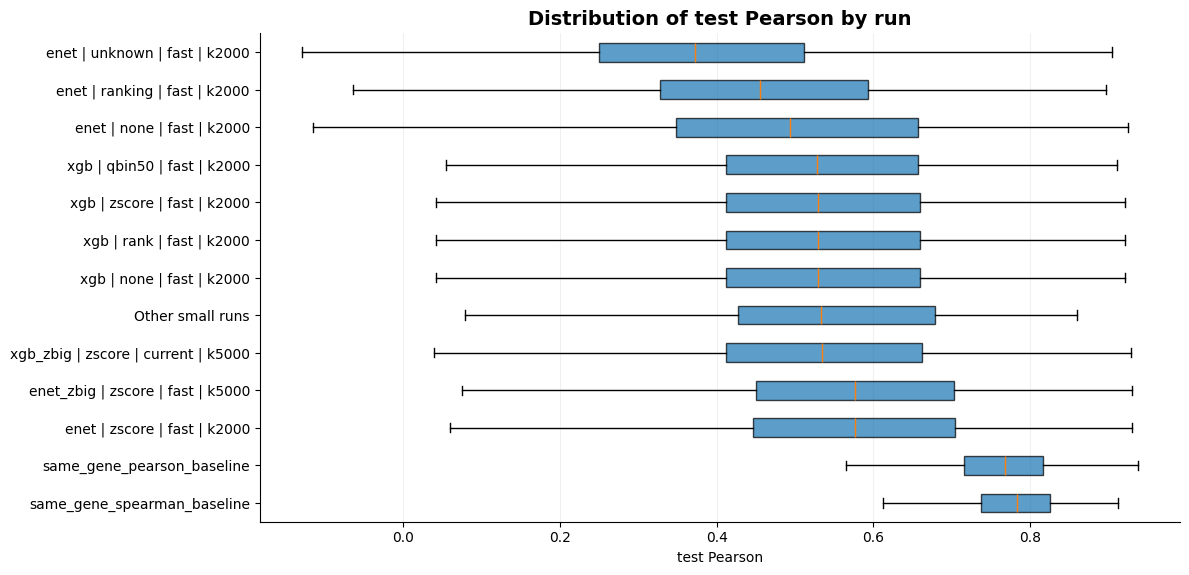

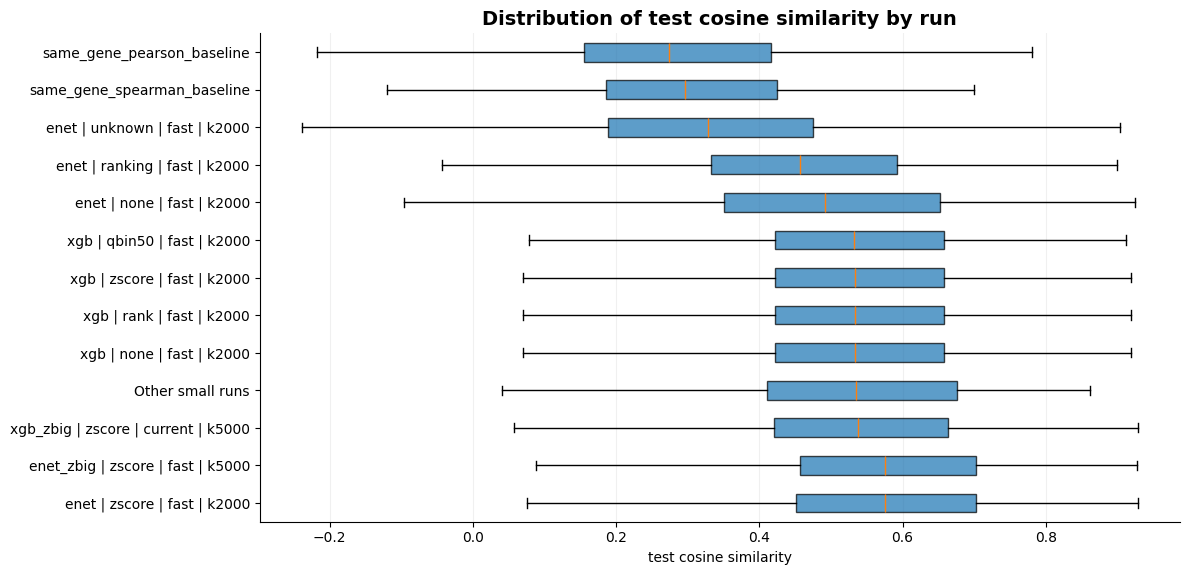

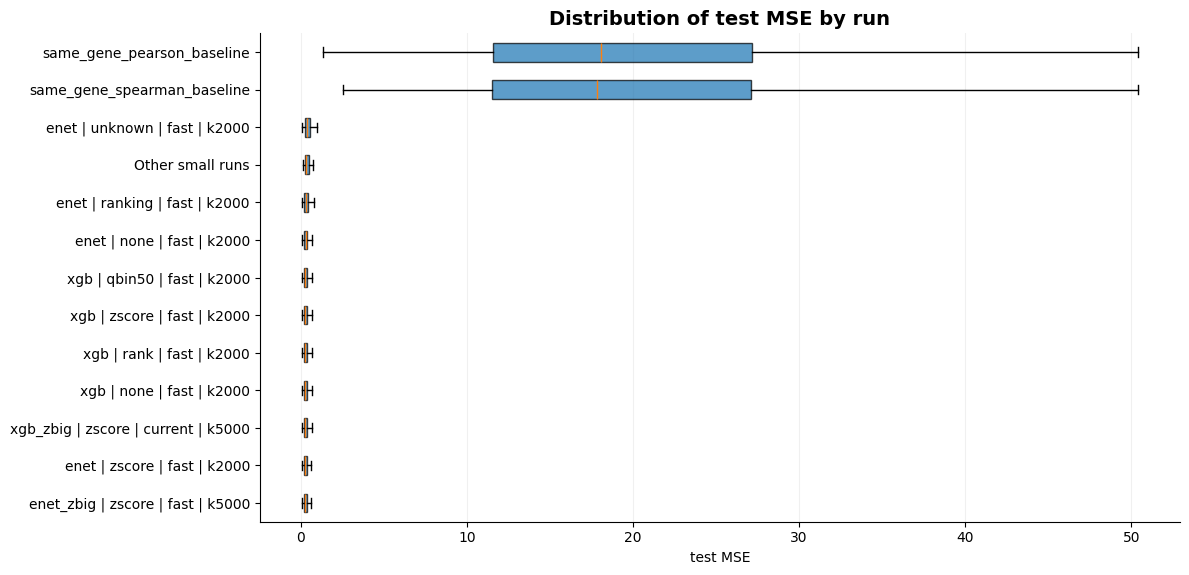

In [ ]:
def plot_metric_distributions(df):
    if df.empty:
        print("No data to plot.")
        return

    plot_df = df.copy()
    # Keep run labels with enough rows visible; group tiny labels for readability.
    counts = plot_df.groupby("run_label")["protein"].nunique()
    keep = counts[counts >= MIN_PROTEINS_TO_SHOW_AS_OWN_SEGMENT].index
    plot_df["plot_label"] = np.where(plot_df["run_label"].isin(keep), plot_df["run_label"], "Other small runs")

    for metric, title, xlabel in [
        ("test_pearson_corr", "Distribution of test Pearson by run", "test Pearson"),
        ("test_cosine_similarity", "Distribution of test cosine similarity by run", "test cosine similarity"),
        ("test_mse", "Distribution of test MSE by run", "test MSE"),
    ]:
        use = plot_df.dropna(subset=[metric]).copy()
        if use.empty:
            print(f"No valid values for {metric}")
            continue

        labels = list(use.groupby("plot_label")[metric].median().sort_values(ascending=(metric == "test_mse")).index)
        data = [use.loc[use["plot_label"] == lab, metric].values for lab in labels]

        fig, ax = plt.subplots(figsize=(12, max(4, 0.45 * len(labels))))
        bp = ax.boxplot(data, vert=False, labels=labels, patch_artist=True, showfliers=False)
        for patch in bp["boxes"]:
            patch.set_alpha(0.72)
        ax.set_title(title, fontsize=14, weight="bold")
        ax.set_xlabel(xlabel)
        ax.grid(axis="x", alpha=0.18)
        ax.spines[["top", "right"]].set_visible(False)
        plt.tight_layout()
        plt.show()

plot_metric_distributions(all_results)

## 8. Protein partition bars: which model/run predicts proteins well?

For each metric, the bar represents all proteins with a valid metric. Good proteins are assigned to the model/run that is best for that protein. Bad proteins are grouped in red.


test_pearson_corr family summary
--------------------------------------------------------------------------------
Total proteins with valid metric: 5113
Good proteins: 1438 (28.1%)
Bad proteins:  3675 (71.9%)
Good proteins best predicted by XGB:                221
Good proteins best predicted by ENet:               1024
Good proteins best predicted by same-gene baseline: 193

Visible bar segments:


,partition_label,proteins,median_metric
0,enet_zbig | zscore | fast | k5000,453,0.771862
1,enet | zscore | fast | k2000,375,0.762567
2,Other good models (<200 proteins each),610,0.803017
3,Bad / test_pearson_corr < 0.7,3675,0.532190



Hidden individual good segments with < 200 proteins:


,partition_label,proteins,median_metric
2,enet | none | fast | k2000,167,0.803307
3,xgb_zbig | zscore | current | k5000,116,0.776627
4,same_gene_pearson_baseline,111,0.819897
5,same_gene_spearman_baseline,82,0.828158
6,xgb | qbin50 | fast | k2000,47,0.795720
7,xgb | none | fast | k2000,23,0.789468
8,xgb | zscore | fast | k2000,20,0.767159
9,xgb | rank | fast | k2000,15,0.750370
10,enet | ranking | fast | k2000,12,0.814806
11,enet | unknown | fast | k2000,11,0.802234


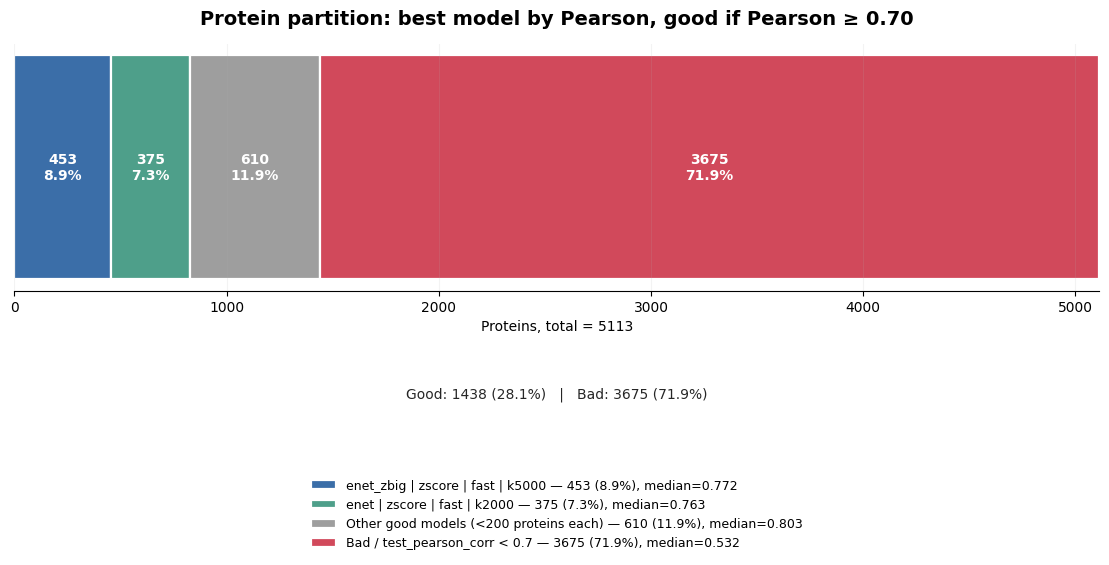


test_cosine_similarity family summary
--------------------------------------------------------------------------------
Total proteins with valid metric: 5113
Good proteins: 1427 (27.9%)
Bad proteins:  3686 (72.1%)
Good proteins best predicted by XGB:                264
Good proteins best predicted by ENet:               1163
Good proteins best predicted by same-gene baseline: 0

Visible bar segments:


,partition_label,proteins,median_metric
0,enet_zbig | zscore | fast | k5000,495,0.772566
1,enet | zscore | fast | k2000,411,0.765593
2,enet | none | fast | k2000,218,0.802352
3,Other good models (<200 proteins each),303,0.786334
4,Bad / test_cosine_similarity < 0.7,3686,0.538288



Hidden individual good segments with < 200 proteins:


,partition_label,proteins,median_metric
3,xgb_zbig | zscore | current | k5000,140,0.782970
4,xgb | qbin50 | fast | k2000,53,0.803460
5,xgb | zscore | fast | k2000,29,0.769789
6,xgb | none | fast | k2000,25,0.798504
7,enet | ranking | fast | k2000,21,0.808982
8,xgb | rank | fast | k2000,17,0.764760
9,enet | unknown | fast | k2000,12,0.789729
10,enet | zscore | fast | k500,5,0.752397
11,enet | none | fast | k500,1,0.804383


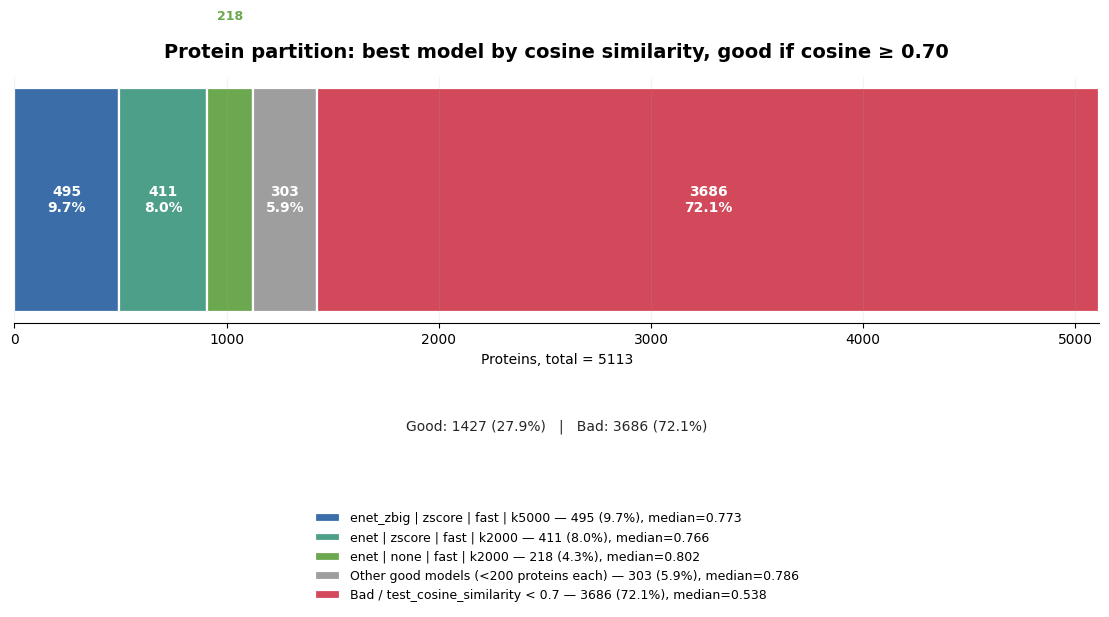


test_mse family summary
--------------------------------------------------------------------------------
Total proteins with valid metric: 5113
Good proteins: 1279 (25.0%)
Bad proteins:  3834 (75.0%)
Good proteins best predicted by XGB:                523
Good proteins best predicted by ENet:               756
Good proteins best predicted by same-gene baseline: 0

Visible bar segments:


,partition_label,proteins,median_metric
0,enet_zbig | zscore | fast | k5000,429,0.150702
1,xgb_zbig | zscore | current | k5000,206,0.143190
2,Other good models (<200 proteins each),644,0.149085
3,Bad / test_mse > 0.182932,3834,0.293775



Hidden individual good segments with < 200 proteins:


,partition_label,proteins,median_metric
2,enet | zscore | fast | k2000,194,0.151693
3,xgb | qbin50 | fast | k2000,154,0.145917
4,enet | none | fast | k2000,67,0.155073
5,xgb | none | fast | k2000,64,0.147023
6,xgb | zscore | fast | k2000,58,0.151057
7,enet | ranking | fast | k2000,50,0.139284
8,xgb | rank | fast | k2000,41,0.153398
9,enet | unknown | fast | k2000,16,0.131929


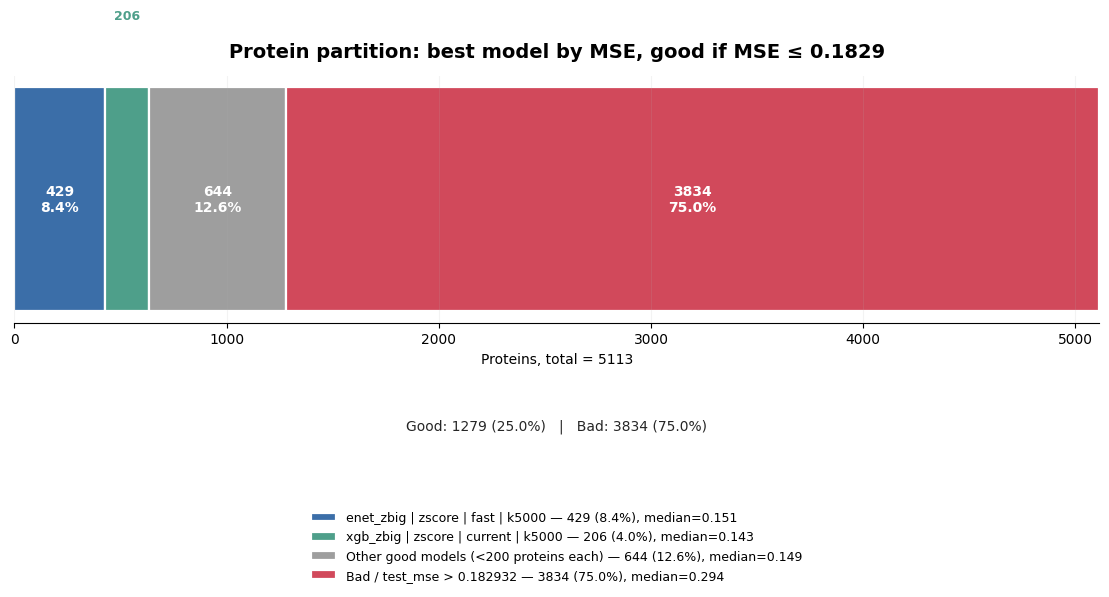

In [ ]:
def is_xgb_label(label: str) -> bool:
    return "xgb" in str(label).lower()


def is_enet_label(label: str) -> bool:
    return "enet" in str(label).lower()


def is_baseline_label(label: str) -> bool:
    label = str(label).lower()
    return "same_gene" in label or "baseline" in label


def make_partition_table(best_df, metric, threshold, higher=True, min_proteins_to_show=200):
    df = best_df.copy()
    df = df.dropna(subset=[metric]).copy()

    if df.empty:
        empty = pd.DataFrame(columns=["partition_label", "proteins", "median_metric", "is_bad", "is_other"])
        return empty, empty, "Bad"

    if higher:
        df["is_good"] = df[metric] >= threshold
        bad_label = f"Bad / {metric} < {threshold:g}"
    else:
        df["is_good"] = df[metric] <= threshold
        bad_label = f"Bad / {metric} > {threshold:g}"

    df["partition_label_raw"] = np.where(df["is_good"], df["run_label"], bad_label)

    raw_part = (
        df.groupby("partition_label_raw", dropna=False)
        .agg(proteins=("protein", "nunique"), median_metric=(metric, "median"))
        .reset_index()
        .rename(columns={"partition_label_raw": "partition_label"})
    )
    raw_part["is_bad"] = raw_part["partition_label"].eq(bad_label)
    raw_part["is_other"] = False

    # Hide small good segments in the bar, but keep them visible in the printed table.
    small_good_labels = raw_part.loc[
        (~raw_part["is_bad"]) & (raw_part["proteins"] < int(min_proteins_to_show)),
        "partition_label",
    ].tolist()

    df["partition_label"] = df["partition_label_raw"]
    if small_good_labels:
        df.loc[
            df["partition_label_raw"].isin(small_good_labels),
            "partition_label",
        ] = f"Other good models (<{min_proteins_to_show} proteins each)"

    part = (
        df.groupby("partition_label", dropna=False)
        .agg(proteins=("protein", "nunique"), median_metric=(metric, "median"))
        .reset_index()
    )
    part["is_bad"] = part["partition_label"].eq(bad_label)
    part["is_other"] = part["partition_label"].str.startswith("Other good models")
    part = part.sort_values(["is_bad", "is_other", "proteins"], ascending=[True, True, False]).reset_index(drop=True)
    raw_part = raw_part.sort_values(["is_bad", "proteins"], ascending=[True, False]).reset_index(drop=True)

    return part, raw_part, bad_label


def print_family_summary(best_df, metric, threshold, higher=True):
    df = best_df.dropna(subset=[metric]).copy()
    if df.empty:
        print(f"No valid values for {metric}")
        return

    df["is_good"] = df[metric] >= threshold if higher else df[metric] <= threshold
    good = df[df["is_good"]]
    bad = df[~df["is_good"]]

    xgb_good = int(good["run_label"].map(is_xgb_label).sum())
    enet_good = int(good["run_label"].map(is_enet_label).sum())
    baseline_good = int(good["run_label"].map(is_baseline_label).sum())
    other_good = len(good) - xgb_good - enet_good - baseline_good

    print(f"\n{metric} family summary")
    print("-" * 80)
    print(f"Total proteins with valid metric: {len(df)}")
    print(f"Good proteins: {len(good)} ({100 * len(good) / len(df):.1f}%)")
    print(f"Bad proteins:  {len(bad)} ({100 * len(bad) / len(df):.1f}%)")
    print(f"Good proteins best predicted by XGB:                {xgb_good}")
    print(f"Good proteins best predicted by ENet:               {enet_good}")
    print(f"Good proteins best predicted by same-gene baseline: {baseline_good}")
    if other_good > 0:
        print(f"Good proteins best predicted by other labels:       {other_good}")


def plot_partition_bar(best_df, metric, threshold, higher=True, title=None, min_proteins_to_show=200):
    part, raw_part, bad_label = make_partition_table(
        best_df,
        metric,
        threshold,
        higher=higher,
        min_proteins_to_show=min_proteins_to_show,
    )
    total = int(part["proteins"].sum())

    if total == 0:
        print(f"No data for {metric}")
        return part

    bad_n = int(part.loc[part["partition_label"].eq(bad_label), "proteins"].sum())
    good_n = total - bad_n

    print_family_summary(best_df, metric, threshold, higher=higher)

    print("\nVisible bar segments:")
    display(part[["partition_label", "proteins", "median_metric"]])

    hidden = raw_part[(~raw_part["is_bad"]) & (raw_part["proteins"] < min_proteins_to_show)].copy()
    if len(hidden):
        print(f"\nHidden individual good segments with < {min_proteins_to_show} proteins:")
        display(hidden[["partition_label", "proteins", "median_metric"]])

    base_colors = [
        "#3B6EA8",
        "#4E9F8A",
        "#6BA84F",
        "#F2A65A",
        "#9D79BC",
        "#7A6F9B",
        "#D6A77A",
        "#8FB8DE",
        "#A1C181",
    ]
    bad_color = "#D1495B"
    other_color = "#9E9E9E"

    color_map = {}
    color_i = 0
    for label in part["partition_label"]:
        if label == bad_label:
            color_map[label] = bad_color
        elif str(label).startswith("Other good models"):
            color_map[label] = other_color
        else:
            color_map[label] = base_colors[color_i % len(base_colors)]
            color_i += 1

    fig, ax = plt.subplots(figsize=(14, 3.2))
    left = 0
    handles, labels = [], []

    for _, row in part.iterrows():
        width = int(row["proteins"])
        label = row["partition_label"]
        pct = 100 * width / total
        color = color_map[label]

        bar = ax.barh(
            [0],
            [width],
            left=left,
            height=0.48,
            color=color,
            edgecolor="white",
            linewidth=1.6,
        )

        if pct >= 5:
            ax.text(
                left + width / 2,
                0,
                f"{width}\n{pct:.1f}%",
                ha="center",
                va="center",
                color="white",
                fontsize=10,
                weight="bold",
            )
        elif width > 0:
            ax.text(
                left + width / 2,
                0.38,
                f"{width}",
                ha="center",
                va="bottom",
                color=color,
                fontsize=9,
                weight="bold",
            )

        med = row["median_metric"]
        label_text = f"{label} — {width} ({pct:.1f}%)"
        if np.isfinite(med):
            label_text += f", median={med:.3g}"

        labels.append(label_text)
        handles.append(bar[0])
        left += width

    ax.set_xlim(0, total)
    ax.set_yticks([])
    ax.set_xlabel(f"Proteins, total = {total}", fontsize=10)
    ax.set_title(
        title or f"Best model per protein by {metric}",
        fontsize=14,
        weight="bold",
        pad=14,
    )
    ax.text(
        0.5,
        -0.42,
        f"Good: {good_n} ({100 * good_n / total:.1f}%)   |   Bad: {bad_n} ({100 * bad_n / total:.1f}%)",
        ha="center",
        va="center",
        transform=ax.transAxes,
        fontsize=10,
        alpha=0.85,
    )
    ax.grid(axis="x", alpha=0.15)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.72),
        ncol=1,
        frameon=False,
        fontsize=9,
    )
    plt.tight_layout()
    plt.show()

    return part


partition_pearson = plot_partition_bar(
    best_pearson,
    metric="test_pearson_corr",
    threshold=PEARSON_GOOD_THRESHOLD,
    higher=True,
    title=f"Protein partition: best model by Pearson, good if Pearson ≥ {PEARSON_GOOD_THRESHOLD:.2f}",
    min_proteins_to_show=MIN_PROTEINS_TO_SHOW_AS_OWN_SEGMENT,
)

partition_cosine = plot_partition_bar(
    best_cosine,
    metric="test_cosine_similarity",
    threshold=COSINE_GOOD_THRESHOLD,
    higher=True,
    title=f"Protein partition: best model by cosine similarity, good if cosine ≥ {COSINE_GOOD_THRESHOLD:.2f}",
    min_proteins_to_show=MIN_PROTEINS_TO_SHOW_AS_OWN_SEGMENT,
)

partition_mse = plot_partition_bar(
    best_mse,
    metric="test_mse",
    threshold=mse_threshold,
    higher=False,
    title=f"Protein partition: best model by MSE, good if MSE ≤ {mse_threshold:.4g}",
    min_proteins_to_show=MIN_PROTEINS_TO_SHOW_AS_OWN_SEGMENT,
)

## 9. Inspect one winning result

This cell loads only metadata from the selected row. It does not retrain models.

In [ ]:
if len(best_pearson) == 0:
    print("No best Pearson row available.")
else:
    row = best_pearson.iloc[0]
    print("Best Pearson example")
    print("- Protein:", row["protein"])
    print("- Run label:", row["run_label"])
    print("- Pearson:", row["test_pearson_corr"])
    print("- Cosine:", row["test_cosine_similarity"])
    print("- MSE:", row["test_mse"])
    print("- Path:", row.get("h5_path", ""))
    print("- Params:", row.get("best_params", {}))

Best Pearson example
- Protein: MAGEA4
- Run label: same_gene_pearson_baseline
- Pearson: 0.937850997387829
- Cosine: 0.7810234529400871
- MSE: 4.29877422445463
- Path: 
- Params: {'baseline': 'same_name_gene_value', 'full_corr_threshold': 0.7, 'scaled': False}


## 10. Optional saving/export cell

The following cell is intentionally commented out, as requested. Uncomment when exports are needed.

In [ ]:
# OUT_DIR = ROOT / "comparison_with_gene_baselines_outputs"
# OUT_DIR.mkdir(parents=True, exist_ok=True)
#
# all_results.to_csv(OUT_DIR / "all_model_and_baseline_metrics.csv", index=False)
# same_gene_baselines.to_csv(OUT_DIR / "same_gene_baseline_metrics.csv", index=False)
# best_pearson.to_csv(OUT_DIR / "best_by_pearson.csv", index=False)
# best_cosine.to_csv(OUT_DIR / "best_by_cosine.csv", index=False)
# best_mse.to_csv(OUT_DIR / "best_by_mse.csv", index=False)
# partition_pearson.to_csv(OUT_DIR / "partition_by_pearson.csv", index=False)
# partition_cosine.to_csv(OUT_DIR / "partition_by_cosine.csv", index=False)
# partition_mse.to_csv(OUT_DIR / "partition_by_mse.csv", index=False)
#
# print("Saved outputs to:", OUT_DIR)

## Plots

In [ ]:
# ============================================================
# Detailed per-model/per-run metric plots from all_results
# Paste this at the end of the notebook, after all_results exists.
# ============================================================

from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import h5py
except Exception:
    h5py = None

# -----------------------------
# Plot output/settings
# -----------------------------
DETAILED_PLOT_DIR = Path("detailed_metric_plots")
DETAILED_PLOT_DIR.mkdir(parents=True, exist_ok=True)

DETAILED_SAVE_FIGURES = True
DETAILED_SHOW_FIGURES = True
DETAILED_DPI = 160

# If True, tries to estimate R2 from test_mse and Y/test samples.
# This can be slower because it may open many .h5 files.
# Keep False unless we specifically need R2.
DETAILED_ESTIMATE_R2 = False

# If True, includes the same-gene baselines in the automatic plotting loop.
DETAILED_INCLUDE_BASELINES = True

# Set to 1 for literally every run label.
# Set to 200 if we want to skip tiny 5/50-protein test runs.
DETAILED_MIN_PROTEINS_PER_RUN = 1


def _sanitize_filename(text, max_len=160):
    text = str(text)
    text = re.sub(r"[^\w\-\.]+", "_", text)
    text = re.sub(r"_+", "_", text).strip("_")
    return text[:max_len] if len(text) > max_len else text


def _add_panel_label(ax, label):
    ax.text(
        0.01, 0.99, label,
        transform=ax.transAxes,
        fontsize=13,
        fontweight="bold",
        va="top",
        ha="left",
        bbox=dict(
            boxstyle="round,pad=0.2",
            facecolor="white",
            edgecolor="black",
            alpha=0.9,
        ),
    )


def _get_group_colors(group="proteins"):
    if group == "proteins":
        return {
            "pearson": "#F5B041",
            "mse": "#E74C3C",
            "cosine": "#5DADE2",
            "r2": "#AF7AC5",
        }
    elif group == "samples":
        return {
            "pearson": "#F8C471",
            "mse": "#EC7063",
            "cosine": "#85C1E9",
            "r2": "#C39BD3",
        }
    else:
        raise ValueError("group must be either 'samples' or 'proteins'")


def _plot_metric_hist(ax, values, title, xlabel, color, panel_label=None, bins=30):
    values = pd.Series(values, dtype="float64").replace([np.inf, -np.inf], np.nan).dropna()

    ax.set_facecolor("#FFFFFF")

    if len(values) > 0:
        ax.hist(values, bins=bins, color=color, edgecolor="black", alpha=0.8)

        mean_val = values.mean()
        median_val = values.median()

        if np.isfinite(mean_val):
            ax.axvline(mean_val, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_val:.3f}")

        if np.isfinite(median_val):
            ax.axvline(median_val, color="black", linestyle=":", linewidth=2, label=f"Median = {median_val:.3f}")

        ax.legend(fontsize=8, frameon=False)
    else:
        ax.text(
            0.5, 0.5,
            "No valid values",
            ha="center",
            va="center",
            transform=ax.transAxes,
            fontsize=11,
        )

    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_ylabel("Count", fontsize=10)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.grid(axis="y", alpha=0.25)

    for spine in ax.spines.values():
        spine.set_color("#BDC3C7")
        spine.set_linewidth(1.0)

    if panel_label is not None:
        _add_panel_label(ax, panel_label)


def _metric_summary_line(series, name):
    s = pd.Series(series, dtype="float64").replace([np.inf, -np.inf], np.nan).dropna()

    if len(s) == 0:
        return (
            f"{name}:\n"
            f"  Mean: not available\n"
            f"  Min:  not available\n"
            f"  Max:  not available\n"
        )

    return (
        f"{name}:\n"
        f"  Mean: {s.mean():.4f} +/- {s.std():.4f}\n"
        f"  Min:  {s.min():.4f}\n"
        f"  Max:  {s.max():.4f}\n"
    )


def _build_summary_text_from_metric_df(df, title_label="Per-Protein", count_label="Proteins"):
    n_items = len(df)

    summary_text = (
        f"{title_label} Summary\n"
        f"{'=' * 28}\n"
        f"{count_label} (n={n_items})\n\n"
        f"{_metric_summary_line(df.get('pearson', pd.Series(dtype=float)), 'Pearson')}\n"
        f"{_metric_summary_line(df.get('mse', pd.Series(dtype=float)), 'MSE')}\n"
        f"{_metric_summary_line(df.get('cosine', pd.Series(dtype=float)), 'Cosine Similarity')}\n"
        f"{_metric_summary_line(df.get('r2', pd.Series(dtype=float)), 'R²')}"
    )

    return summary_text


def _read_h5_string_list(path, candidates=None):
    """
    Tries to read test sample names from the H5 files.
    Used only if DETAILED_ESTIMATE_R2=True.
    """
    if h5py is None:
        return None

    if candidates is None:
        candidates = [
            "samples/test_samples",
            "test_samples",
            "data/test_samples",
            "split/test_samples",
        ]

    path = Path(path)
    if not path.exists():
        return None

    try:
        with h5py.File(path, "r") as h5:
            for key in candidates:
                if key not in h5:
                    continue

                arr = h5[key][()]
                arr = np.asarray(arr).ravel()

                out = []
                for x in arr:
                    if isinstance(x, bytes):
                        out.append(x.decode("utf-8"))
                    else:
                        out.append(str(x))

                return pd.Index(out)
    except Exception:
        return None

    return None


_TEST_SAMPLE_CACHE = {}


def _estimate_r2_for_row(row):
    """
    Estimate R2 from stored MSE and the true Y values.

    R2 = 1 - SS_res / SS_tot
    If MSE is mean squared error on the test set, SS_res = MSE * n.

    This is only an estimate because it assumes the stored MSE used the same
    finite test values we recover here.
    """
    if "Y" not in globals():
        return np.nan

    protein = str(row.get("protein", ""))
    mse_val = row.get("mse", row.get("test_mse", np.nan))

    if protein not in Y.columns:
        return np.nan

    if not np.isfinite(mse_val):
        return np.nan

    h5_path = str(row.get("h5_path", ""))

    samples = None

    if h5_path and h5_path.lower() != "nan":
        if h5_path not in _TEST_SAMPLE_CACHE:
            _TEST_SAMPLE_CACHE[h5_path] = _read_h5_string_list(h5_path)
        samples = _TEST_SAMPLE_CACHE[h5_path]

    # Baselines in this notebook use the global test_samples variable.
    if samples is None and "test_samples" in globals():
        samples = pd.Index(test_samples)

    if samples is None:
        return np.nan

    samples = pd.Index(samples).intersection(Y.index)

    if len(samples) <= 1:
        return np.nan

    y_true = pd.to_numeric(Y.loc[samples, protein], errors="coerce").to_numpy(dtype=float)
    y_true = y_true[np.isfinite(y_true)]

    if len(y_true) <= 1:
        return np.nan

    ss_tot = float(np.sum((y_true - np.mean(y_true)) ** 2))
    if ss_tot <= 0:
        return np.nan

    ss_res = float(mse_val) * len(y_true)
    return 1.0 - ss_res / ss_tot


def make_per_protein_metric_df(
    results_df,
    run_label=None,
    model_family=None,
    source_folder=None,
    estimate_r2=False,
    sort_by="pearson",
):
    """
    Converts the notebook's all_results table into the dataframe expected
    by the detailed plot.

    Required all_results columns:
      - protein
      - test_pearson_corr
      - test_mse
      - test_cosine_similarity
      - run_label
    """
    df = results_df.copy()

    if run_label is not None:
        if isinstance(run_label, (list, tuple, set, pd.Index, np.ndarray)):
            df = df[df["run_label"].isin(list(run_label))].copy()
        else:
            df = df[df["run_label"].astype(str).eq(str(run_label))].copy()

    if model_family is not None and "model_family" in df.columns:
        if isinstance(model_family, (list, tuple, set, pd.Index, np.ndarray)):
            df = df[df["model_family"].isin(list(model_family))].copy()
        else:
            df = df[df["model_family"].astype(str).eq(str(model_family))].copy()

    if source_folder is not None and "source_folder" in df.columns:
        if isinstance(source_folder, (list, tuple, set, pd.Index, np.ndarray)):
            df = df[df["source_folder"].isin(list(source_folder))].copy()
        else:
            df = df[df["source_folder"].astype(str).eq(str(source_folder))].copy()

    if df.empty:
        return pd.DataFrame(columns=["protein", "pearson", "mse", "cosine", "r2", "run_label"])

    out = pd.DataFrame({
        "protein": df["protein"].astype(str).values,
        "pearson": pd.to_numeric(df.get("test_pearson_corr", np.nan), errors="coerce").values,
        "mse": pd.to_numeric(df.get("test_mse", np.nan), errors="coerce").values,
        "cosine": pd.to_numeric(df.get("test_cosine_similarity", np.nan), errors="coerce").values,
        "run_label": df.get("run_label", pd.Series(["unknown"] * len(df))).astype(str).values,
    })

    # Keep useful metadata if present.
    for col in ["model_family", "source_folder", "normalization", "grid_preset", "select_k", "h5_path", "file"]:
        if col in df.columns:
            out[col] = df[col].values

    # R2 is not directly stored in the notebook's all_results.
    if "test_r2" in df.columns:
        out["r2"] = pd.to_numeric(df["test_r2"], errors="coerce").values
    elif "r2" in df.columns:
        out["r2"] = pd.to_numeric(df["r2"], errors="coerce").values
    else:
        out["r2"] = np.nan

    if estimate_r2:
        out["r2"] = out.apply(_estimate_r2_for_row, axis=1)

    # If a filtered set accidentally contains duplicate proteins,
    # keep the better one by the requested metric.
    if sort_by == "mse":
        out = (
            out.sort_values("mse", ascending=True, na_position="last")
               .drop_duplicates("protein", keep="first")
               .reset_index(drop=True)
        )
    elif sort_by == "cosine":
        out = (
            out.sort_values("cosine", ascending=False, na_position="last")
               .drop_duplicates("protein", keep="first")
               .reset_index(drop=True)
        )
    else:
        out = (
            out.sort_values("pearson", ascending=False, na_position="last")
               .drop_duplicates("protein", keep="first")
               .reset_index(drop=True)
        )

    return out


def plot_detailed(
    per_sample_df=None,
    per_protein_df=None,
    *legacy_args,
    group="proteins",
    out_path=None,
    title=None,
    show=True,
):
    """
    Detailed plot function compatible with the style of the function shared earlier.

    In this notebook, the natural use is:
        plot_detailed(per_protein_df=my_df, group="proteins")

    Expected per_protein_df columns:
        protein, pearson, mse, cosine, r2

    R2 may be all NaN; the R2 panel will show "No valid values".
    """
    if group not in {"samples", "proteins"}:
        raise ValueError("group must be either 'samples' or 'proteins'")

    colors = _get_group_colors(group)

    if group == "samples":
        if per_sample_df is None:
            raise ValueError("per_sample_df is required when group='samples'")
        df = per_sample_df.copy()
        item_col = "sample"
        title_prefix = "Per-Sample"
        count_label = "Samples"
    else:
        if per_protein_df is None:
            raise ValueError("per_protein_df is required when group='proteins'")
        df = per_protein_df.copy()
        item_col = "protein"
        title_prefix = "Per-Protein"
        count_label = "Proteins"

    for needed_col in [item_col, "pearson", "mse", "cosine"]:
        if needed_col not in df.columns:
            raise ValueError(f"Missing required column: {needed_col}")

    if "r2" not in df.columns:
        df["r2"] = np.nan

    for col in ["pearson", "mse", "cosine", "r2"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    fig = plt.figure(figsize=(16, 10))
    fig.patch.set_facecolor("#F8F9FA")
    gs = fig.add_gridspec(2, 3, hspace=0.35, wspace=0.32)

    if title is not None:
        fig.suptitle(title, fontsize=16, fontweight="bold", y=0.98)

    ax1 = fig.add_subplot(gs[0, 0])
    _plot_metric_hist(
        ax1,
        df["pearson"],
        f"{title_prefix} PCC",
        "Pearson Correlation",
        colors["pearson"],
        panel_label="a)",
    )

    ax2 = fig.add_subplot(gs[0, 1])
    _plot_metric_hist(
        ax2,
        df["mse"],
        f"{title_prefix} MSE",
        "MSE",
        colors["mse"],
        panel_label="b)",
    )

    ax3 = fig.add_subplot(gs[0, 2])
    _plot_metric_hist(
        ax3,
        df["cosine"],
        f"{title_prefix} Cosine Similarity",
        "Cosine Similarity",
        colors["cosine"],
        panel_label="c)",
    )

    ax4 = fig.add_subplot(gs[1, 0])
    _plot_metric_hist(
        ax4,
        df["r2"],
        f"{title_prefix} R²",
        "R² Score",
        colors["r2"],
        panel_label="d)",
    )

    ax5 = fig.add_subplot(gs[1, 1])

    valid_rank_df = df.dropna(subset=["pearson"]).copy()

    if len(valid_rank_df) > 0:
        best_10 = (
            valid_rank_df.sort_values("pearson", ascending=False, na_position="last")
            .head(10)
            .sort_values("pearson", ascending=True)
        )

        worst_10 = (
            valid_rank_df.sort_values("pearson", ascending=True, na_position="last")
            .head(10)
            .sort_values("pearson", ascending=False)
        )

        combined = pd.concat([best_10, worst_10], axis=0).reset_index(drop=True)
        bar_colors = (["#58D68D"] * len(best_10)) + (["#E74C3C"] * len(worst_10))
        y_pos = np.arange(len(combined))

        ax5.barh(
            y_pos,
            combined["pearson"].values,
            color=bar_colors,
            edgecolor="black",
            alpha=0.8,
        )

        ax5.set_yticks(y_pos)
        ax5.set_yticklabels(combined[item_col].astype(str).values, fontsize=8)
        ax5.axvline(0, color="red", linestyle="-", linewidth=1)
        ax5.set_xlabel("PCC", fontsize=10)
        ax5.set_title(f"Best 10 / Worst 10 {count_label} by PCC", fontsize=12, fontweight="bold")
        ax5.grid(axis="x", alpha=0.25)
    else:
        ax5.text(
            0.5, 0.5,
            "No valid Pearson values",
            ha="center",
            va="center",
            transform=ax5.transAxes,
        )
        ax5.set_title(f"Best 10 / Worst 10 {count_label} by PCC", fontsize=12, fontweight="bold")

    _add_panel_label(ax5, "e)")

    ax6 = fig.add_subplot(gs[1, 2])
    ax6.axis("off")
    ax6.set_title("Summary Statistics", fontsize=12, fontweight="bold")
    _add_panel_label(ax6, "f)")

    summary_text = _build_summary_text_from_metric_df(
        df=df,
        title_label=title_prefix,
        count_label=count_label,
    )

    ax6.text(
        0.5,
        0.92,
        summary_text,
        transform=ax6.transAxes,
        fontsize=9,
        va="top",
        ha="center",
        multialignment="left",
        fontfamily="monospace",
        bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.45),
    )

    if title is not None:
        plt.tight_layout(rect=[0, 0, 1, 0.96])
    else:
        plt.tight_layout()

    if out_path is not None:
        out_path = Path(out_path)
        out_path.parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(out_path, dpi=DETAILED_DPI, bbox_inches="tight", facecolor=fig.get_facecolor())
        print(f"Saved: {out_path}")

    if show:
        plt.show()
    else:
        plt.close(fig)

    return fig


def plot_detailed_for_run_label(
    run_label,
    results_df=None,
    estimate_r2=None,
    save=None,
    show=None,
    out_dir=None,
):
    """
    Plot one model/run from all_results.
    """
    if results_df is None:
        results_df = all_results

    if estimate_r2 is None:
        estimate_r2 = DETAILED_ESTIMATE_R2

    if save is None:
        save = DETAILED_SAVE_FIGURES

    if show is None:
        show = DETAILED_SHOW_FIGURES

    if out_dir is None:
        out_dir = DETAILED_PLOT_DIR

    per_protein_df = make_per_protein_metric_df(
        results_df,
        run_label=run_label,
        estimate_r2=estimate_r2,
        sort_by="pearson",
    )

    if per_protein_df.empty:
        print(f"No rows found for run_label={run_label!r}")
        return None

    safe_name = _sanitize_filename(run_label)
    out_path = Path(out_dir) / f"detailed_{safe_name}.png" if save else None

    title = f"Detailed per-protein metrics: {run_label}"

    fig = plot_detailed(
        per_protein_df=per_protein_df,
        group="proteins",
        out_path=out_path,
        title=title,
        show=show,
    )

    return per_protein_df


def plot_detailed_for_all_run_labels(
    results_df=None,
    min_proteins=None,
    include_baselines=None,
    estimate_r2=None,
    save=None,
    show=None,
    out_dir=None,
):
    """
    Plot every run_label/model present in all_results.
    """
    if results_df is None:
        results_df = all_results

    if min_proteins is None:
        min_proteins = DETAILED_MIN_PROTEINS_PER_RUN

    if include_baselines is None:
        include_baselines = DETAILED_INCLUDE_BASELINES

    counts = (
        results_df.groupby("run_label")["protein"]
        .nunique()
        .sort_values(ascending=False)
    )

    labels = counts[counts >= int(min_proteins)].index.tolist()

    if not include_baselines:
        labels = [
            lab for lab in labels
            if "baseline" not in str(lab).lower() and "same_gene" not in str(lab).lower()
        ]

    print(f"Plotting {len(labels)} run labels")
    print("-" * 80)
    for lab in labels:
        print(f"{lab}  |  proteins={int(counts.loc[lab])}")

    outputs = {}

    for lab in labels:
        print("\n" + "=" * 100)
        print(f"Plotting: {lab}")
        outputs[lab] = plot_detailed_for_run_label(
            lab,
            results_df=results_df,
            estimate_r2=estimate_r2,
            save=save,
            show=show,
            out_dir=out_dir,
        )

    return outputs


def plot_detailed_for_model_family(
    model_family,
    results_df=None,
    estimate_r2=None,
    save=None,
    show=None,
    out_dir=None,
):
    """
    Optional helper: combine all rows for one model_family.
    Example:
        plot_detailed_for_model_family("xgb")
        plot_detailed_for_model_family("enet")
        plot_detailed_for_model_family("same_gene_baseline")
    """
    if results_df is None:
        results_df = all_results

    if estimate_r2 is None:
        estimate_r2 = DETAILED_ESTIMATE_R2

    if save is None:
        save = DETAILED_SAVE_FIGURES

    if show is None:
        show = DETAILED_SHOW_FIGURES

    if out_dir is None:
        out_dir = DETAILED_PLOT_DIR

    per_protein_df = make_per_protein_metric_df(
        results_df,
        model_family=model_family,
        estimate_r2=estimate_r2,
        sort_by="pearson",
    )

    if per_protein_df.empty:
        print(f"No rows found for model_family={model_family!r}")
        return None

    safe_name = _sanitize_filename(f"family_{model_family}")
    out_path = Path(out_dir) / f"detailed_{safe_name}.png" if save else None

    title = f"Detailed per-protein metrics: model_family = {model_family}"

    fig = plot_detailed(
        per_protein_df=per_protein_df,
        group="proteins",
        out_path=out_path,
        title=title,
        show=show,
    )

    return per_protein_df


print("Detailed plotting functions loaded.")
print("Output folder:", DETAILED_PLOT_DIR.resolve())

Detailed plotting functions loaded.
Output folder: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\detailed_metric_plots


Plotting 12 run labels
--------------------------------------------------------------------------------
enet | none | fast | k2000  |  proteins=5113
enet_zbig | zscore | fast | k5000  |  proteins=5113
xgb | zscore | fast | k2000  |  proteins=5113
xgb | rank | fast | k2000  |  proteins=5113
xgb | qbin50 | fast | k2000  |  proteins=5113
xgb | none | fast | k2000  |  proteins=5113
xgb_zbig | zscore | current | k5000  |  proteins=5113
enet | zscore | fast | k2000  |  proteins=5113
enet | unknown | fast | k2000  |  proteins=5113
enet | ranking | fast | k2000  |  proteins=5113
same_gene_pearson_baseline  |  proteins=786
same_gene_spearman_baseline  |  proteins=615

Plotting: enet | none | fast | k2000
Saved: detailed_metric_plots\detailed_enet_none_fast_k2000.png


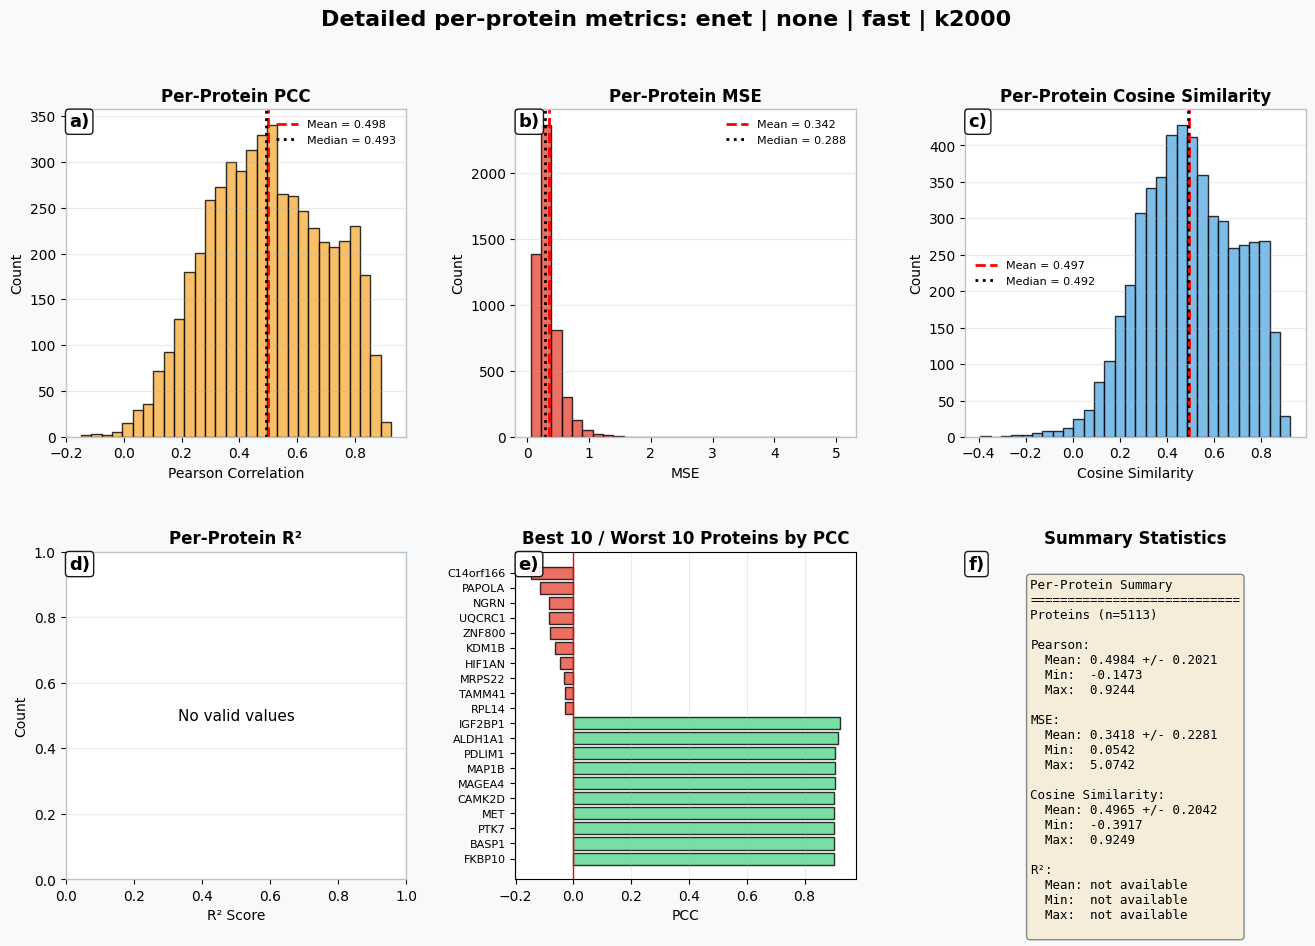


Plotting: enet_zbig | zscore | fast | k5000
Saved: detailed_metric_plots\detailed_enet_zbig_zscore_fast_k5000.png


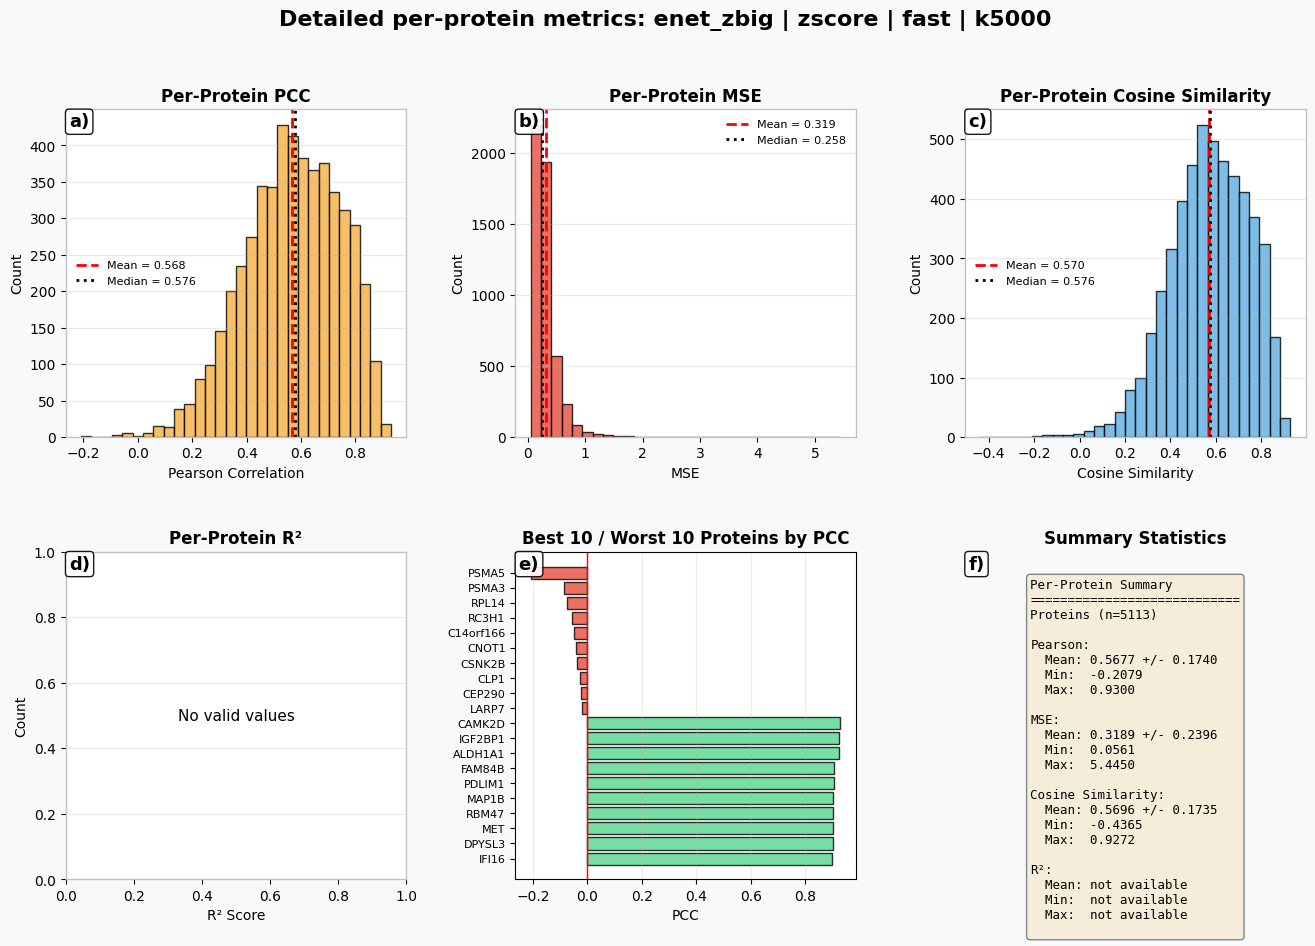


Plotting: xgb | zscore | fast | k2000
Saved: detailed_metric_plots\detailed_xgb_zscore_fast_k2000.png


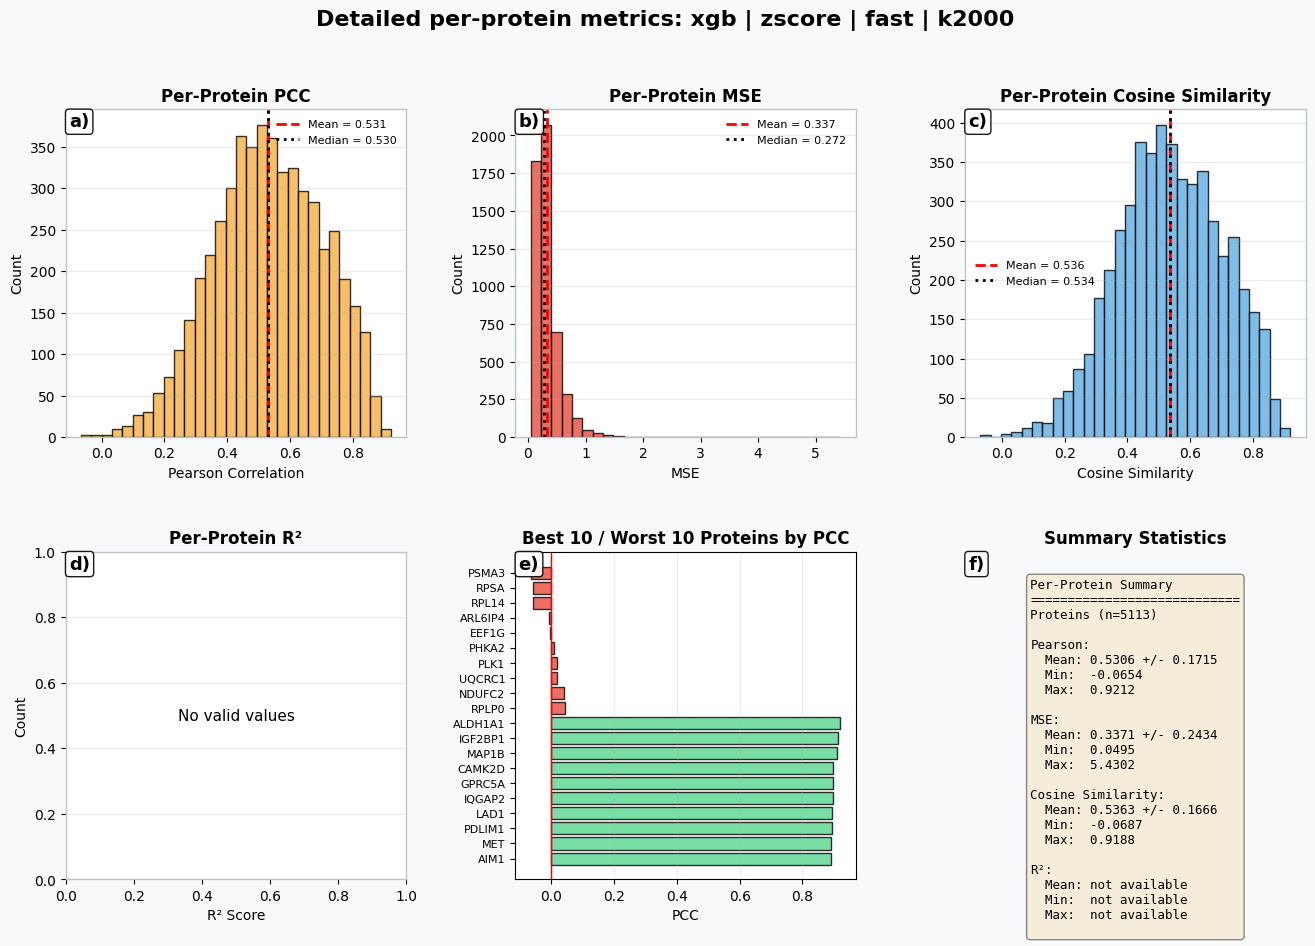


Plotting: xgb | rank | fast | k2000
Saved: detailed_metric_plots\detailed_xgb_rank_fast_k2000.png


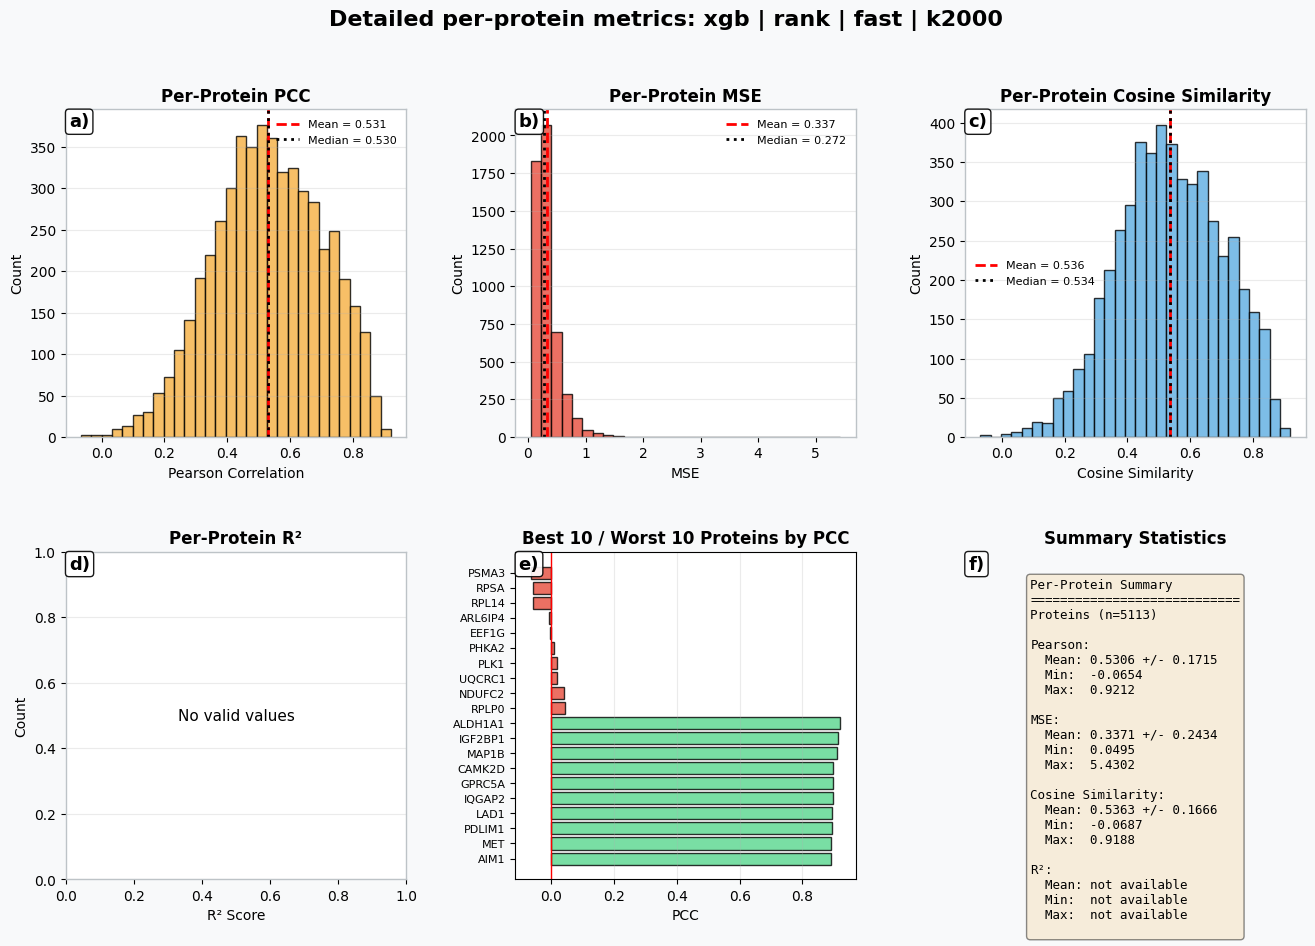


Plotting: xgb | qbin50 | fast | k2000
Saved: detailed_metric_plots\detailed_xgb_qbin50_fast_k2000.png


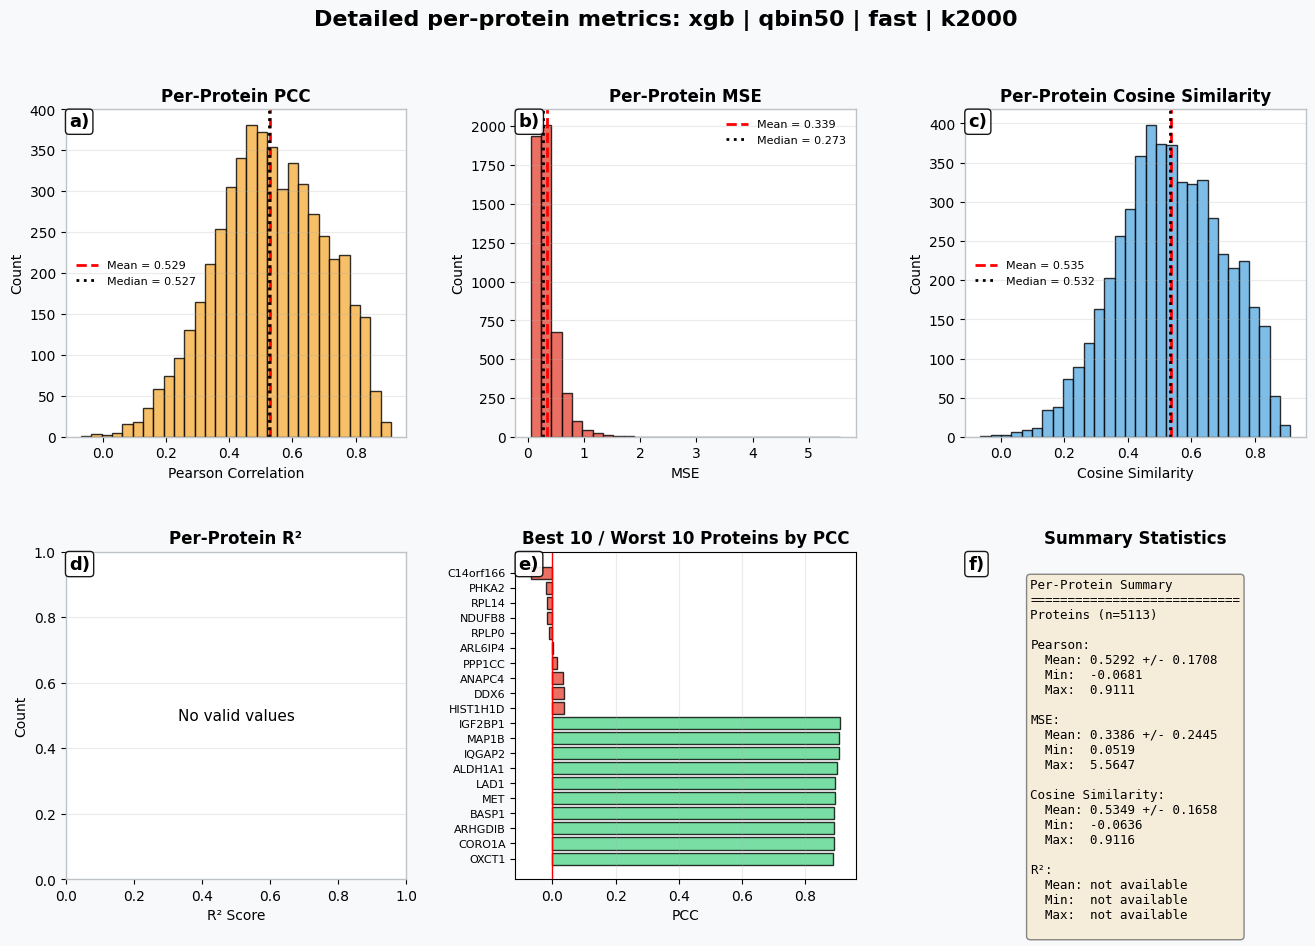


Plotting: xgb | none | fast | k2000
Saved: detailed_metric_plots\detailed_xgb_none_fast_k2000.png


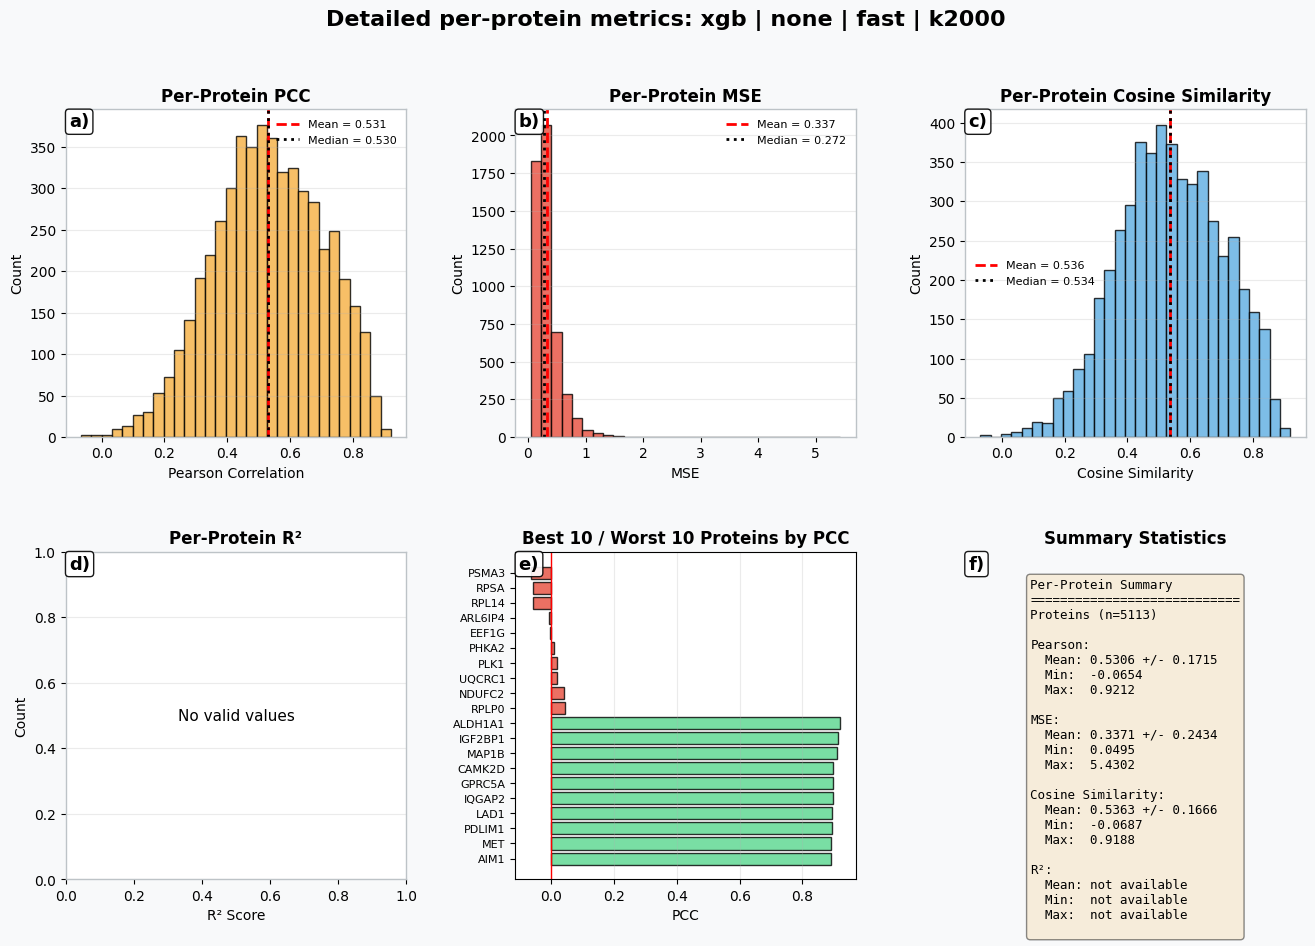


Plotting: xgb_zbig | zscore | current | k5000
Saved: detailed_metric_plots\detailed_xgb_zbig_zscore_current_k5000.png


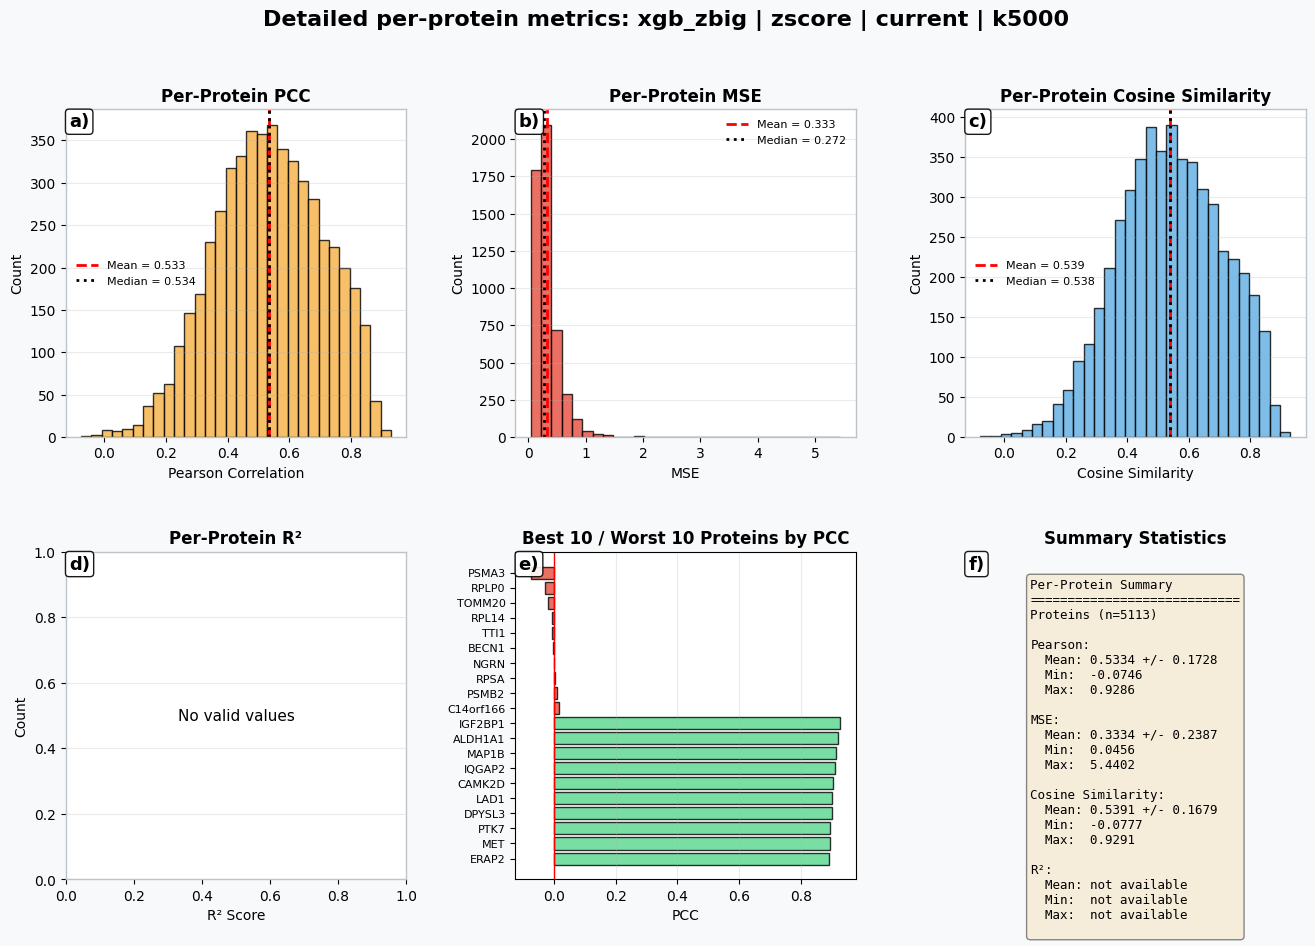


Plotting: enet | zscore | fast | k2000
Saved: detailed_metric_plots\detailed_enet_zscore_fast_k2000.png


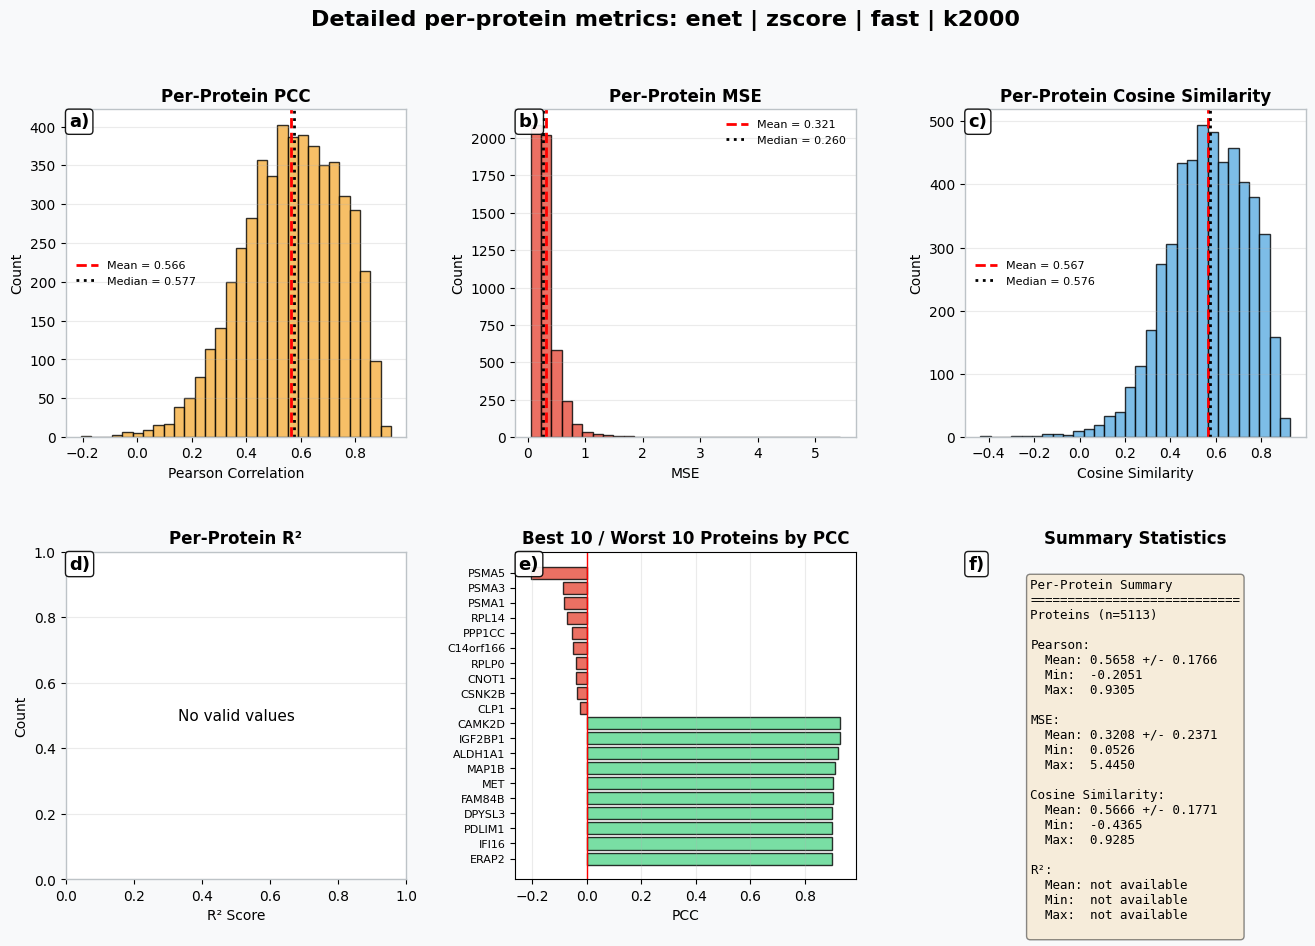


Plotting: enet | unknown | fast | k2000
Saved: detailed_metric_plots\detailed_enet_unknown_fast_k2000.png


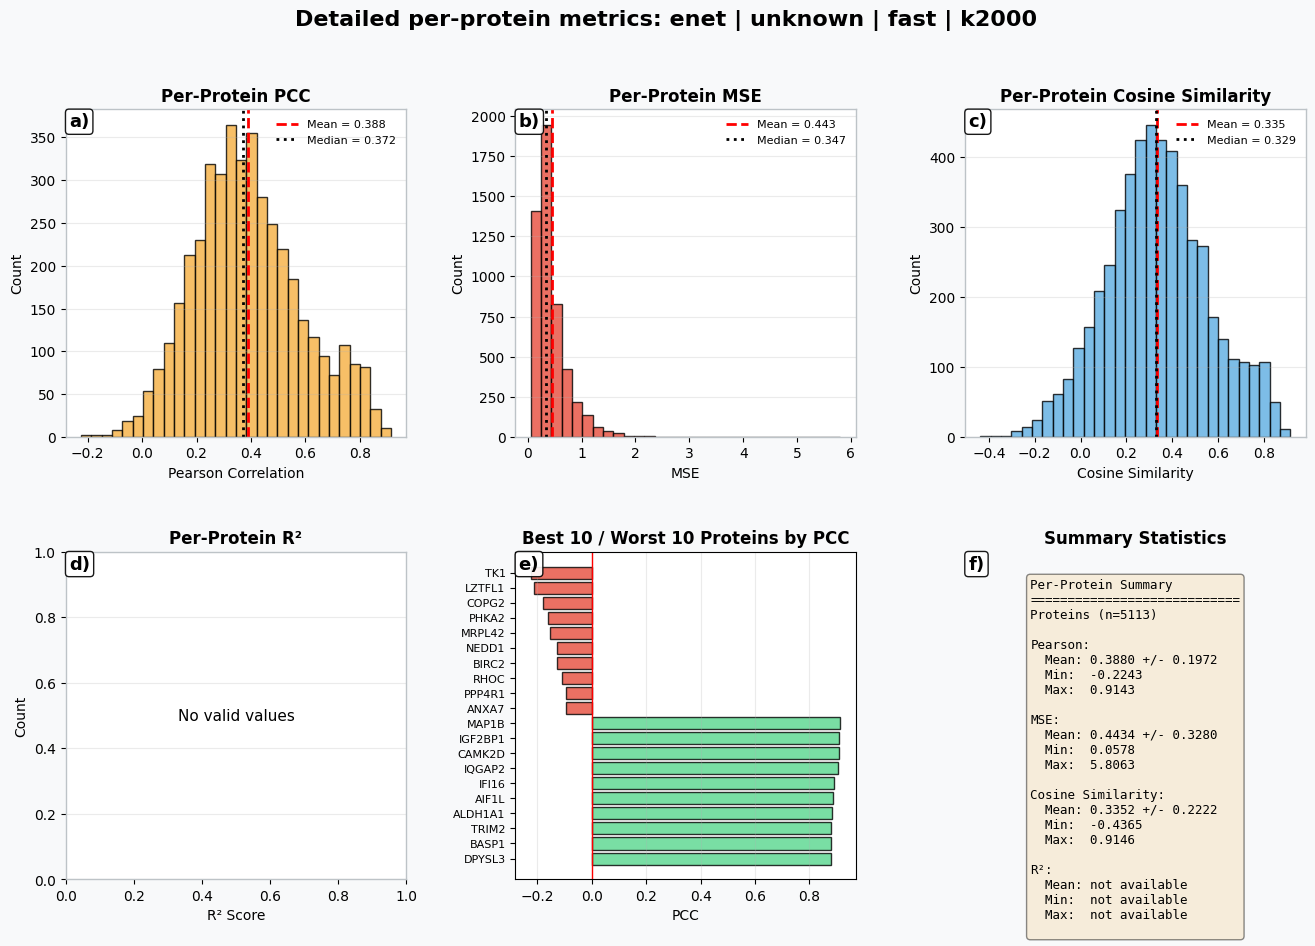


Plotting: enet | ranking | fast | k2000
Saved: detailed_metric_plots\detailed_enet_ranking_fast_k2000.png


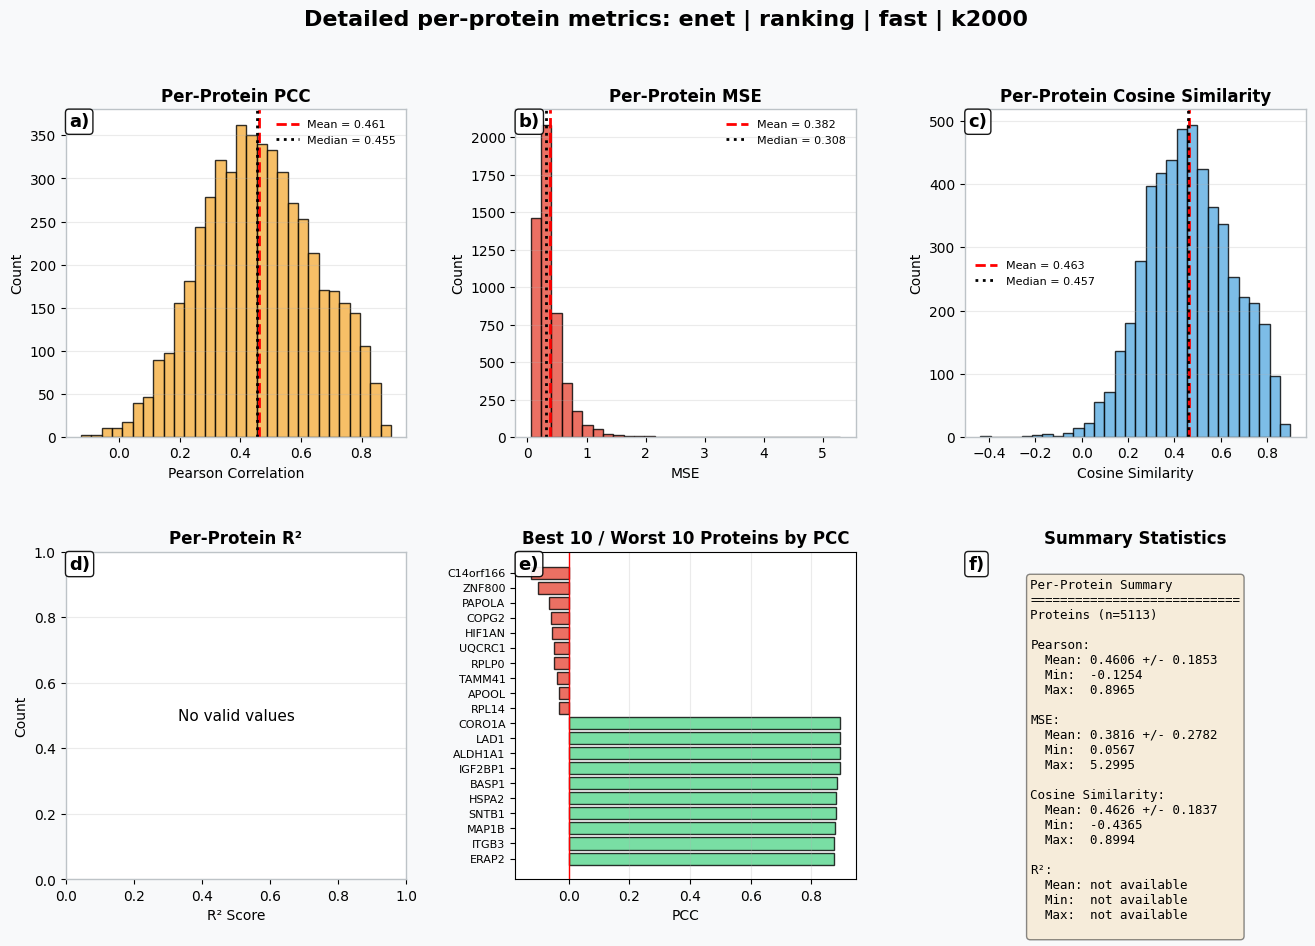


Plotting: same_gene_pearson_baseline
Saved: detailed_metric_plots\detailed_same_gene_pearson_baseline.png


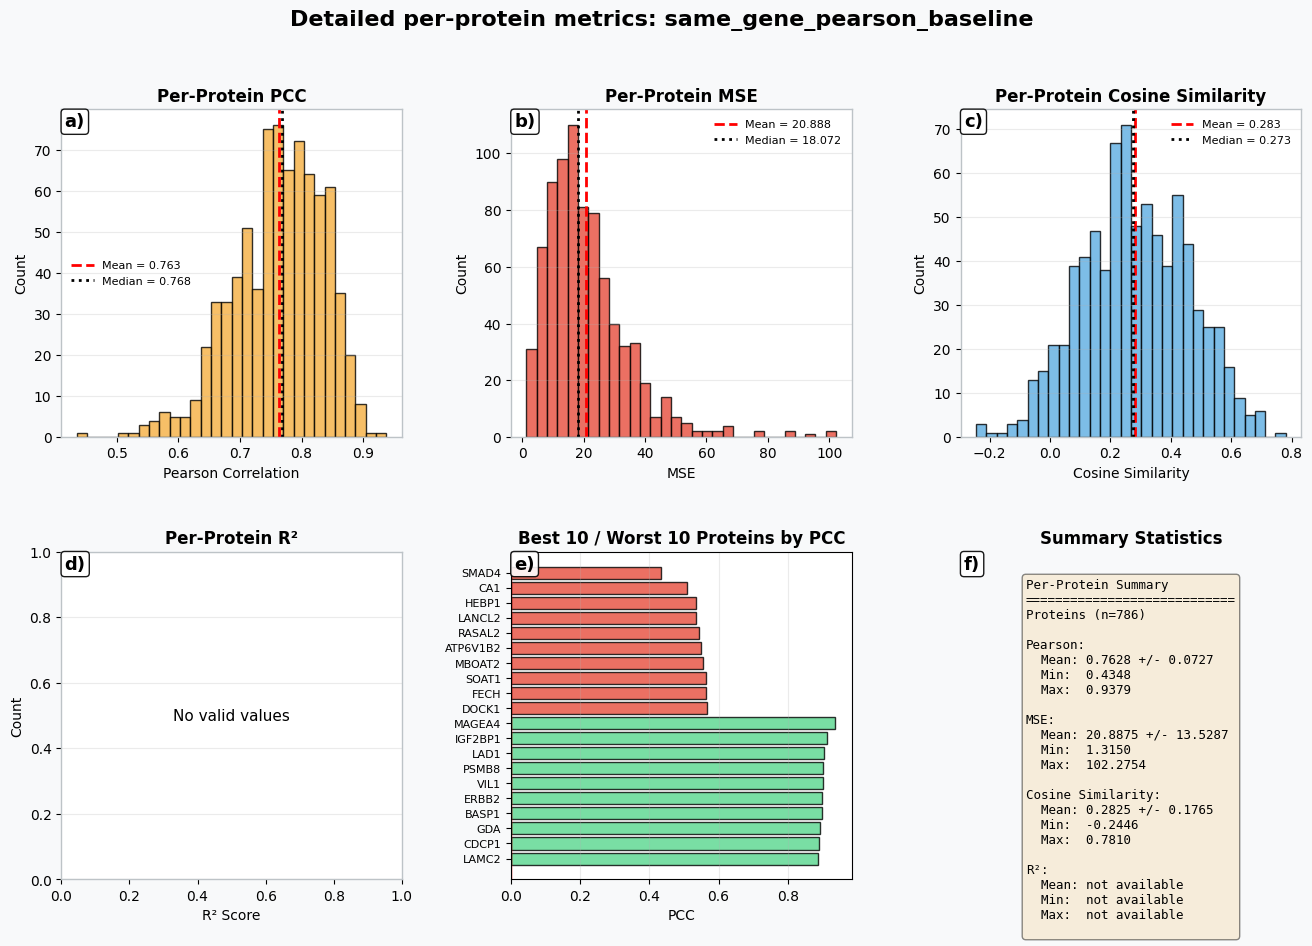


Plotting: same_gene_spearman_baseline
Saved: detailed_metric_plots\detailed_same_gene_spearman_baseline.png


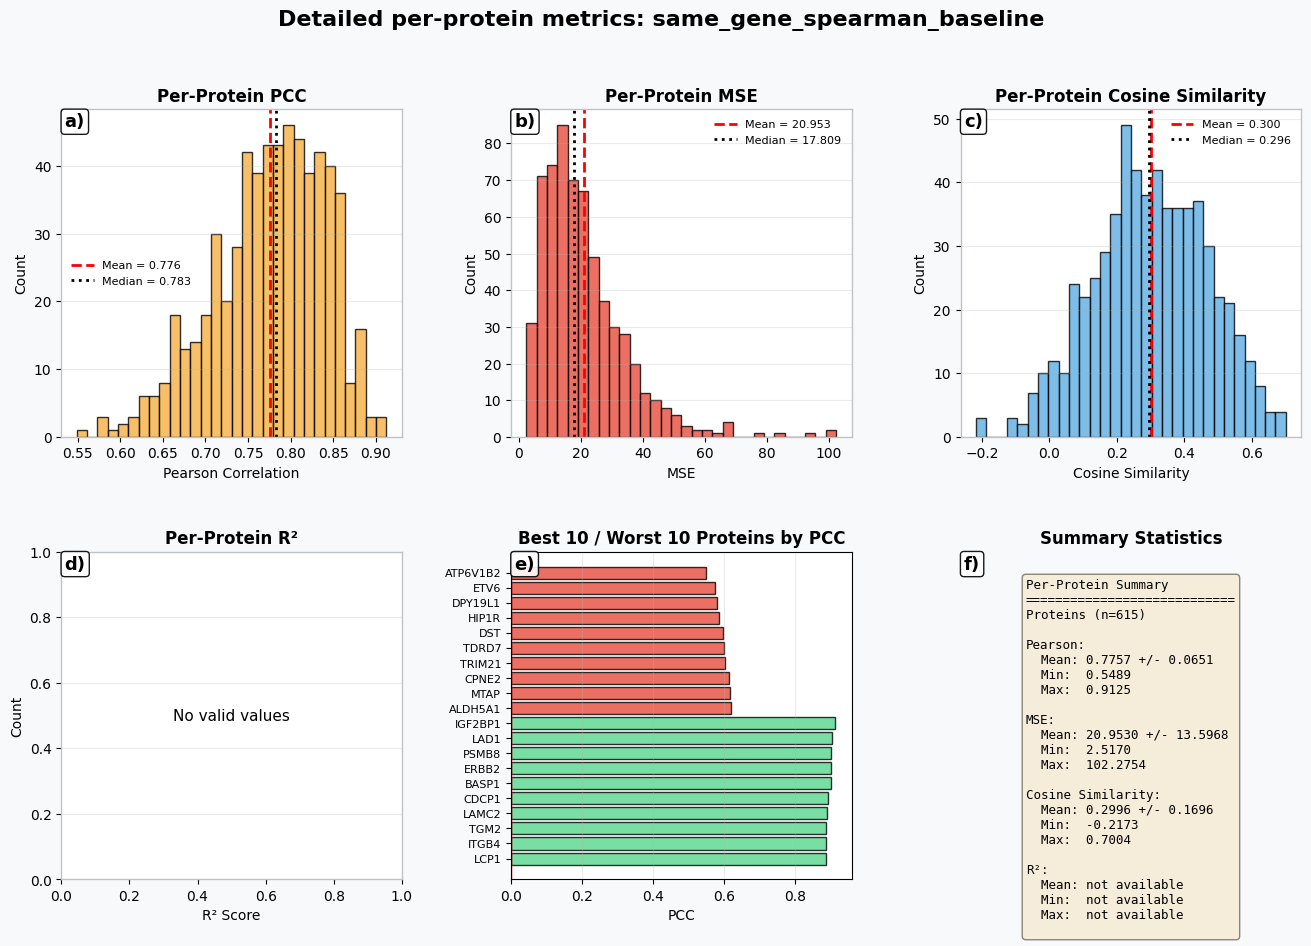

In [ ]:
detailed_outputs_full_runs = plot_detailed_for_all_run_labels(
    all_results,
    min_proteins=200,
    include_baselines=True,
    estimate_r2=False,
    save=True,
    show=True,
    out_dir=DETAILED_PLOT_DIR,
)